# 04B · Robust TCN validation and the frozen shortlist

**Advanced movement representation learning — chapter 4, part B.** Status: `AUTHORED — AWAITING USER EXECUTION` (2026-10-12). No cell has been run by the author.

**Question.** Notebook 03 found that TCN-B on speed against recorded distance (8-dimensional, masked reconstruction + same-athlete attempt consistency) recognises an athlete from his other attempt better than the functional PCA benchmark, and that it depends less on the recording window. Does that survive (1) other training seeds, (2) impostors who share the athlete's stopwatch, position and body size, (3) an audit of the residualisation that made the residual AUC larger than the raw one, (4) fewer dimensions, (5) acquisition and cohort checks, and (6) null controls?

**What this notebook does.** It retrains the SAME encoder with pre-declared seeds (nothing else changes), evaluates every representation with the functions of notebook 03 plus the new checks, and freezes a shortlist of five to eight representation families for the NFL transfer study.

**What it does not do.** No NFL outcome is read and nothing is selected with one. No GRU, LSTM or Transformer is trained. No seed is chosen for its held-out performance. No artifact of notebooks 00–03 is overwritten: everything is written to the `atlas` sub-area.

**Prerequisites.** Notebooks 00–03 and `04a_feature_characteristic_atlas.ipynb` run in the same `RUN_MODE`; PyTorch installed in the kernel's environment. Run `smoke` first (technical check, not interpretable), then `full` after a kernel restart.

## Configuration

In [1]:
RUN_MODE = 'full'       # 'smoke' | 'full' — must match the mode notebooks 00–03 and 04A were run with
FORCE_REBUILD = False    # True = retrain the new seeds and recompute every table
SAVE_FIGURES = True
SAVE_TABLES = True
SAVE_MODELS = True       # checkpoints of the NEW seeds under artifacts/models/advanced_movement/atlas/tcn (never notebook 03's)
SEED = 20261011          # same seed as notebook 00; it is also the training seed of the executed notebook 03
DEVICE = 'auto'          # 'auto' | 'cpu' | 'cuda' (the models are small: CPU is enough)
NUM_WORKERS = 0          # unused: the curves of a fold fit in memory as one tensor
BATCH_SIZE = 32          # athletes per batch — used only if no notebook-03 checkpoint is found

TRAINING_SEEDS = (20261011, 20261012, 20261013)   # declared before running. The FIRST is the primary seed: the executed
                                                  # notebook-03 run, reused from disk. The others are replicates.
MAX_EPOCHS = None        # None = the training budget stored in the notebook-03 checkpoints (recommended).
                         # A number changes the budget, so ALL seeds are then retrained with it.
EMBEDDING_DIMS = (2, 4, 8)   # training-fitted projections of the 8-dimensional embedding
MATCHING_CONFIGURATION = {
    'variables': ['cmb_forty', 'cmb_ten_yd_split', 'cmb_combine_weight', 'cmb_combine_height'],
    'required': ['cmb_forty', 'cmb_ten_yd_split', 'cmb_combine_weight'],
    'k_nearest': 5,          # impostors per athlete, same position and fold
    'caliper': 0.75,         # largest RMS difference, in within-position SD units of the DESIGN athletes
    'scale_role': 'design',  # the athletes the matching scales are computed on (never the read-out athletes)
}
RUN_LEAVE_COHORT_OUT = True   # sensitivity: one extra encoder per draft cohort, trained on the other cohorts
REFREEZE_SHORTLIST = False    # True replaces an already frozen transfer_candidates_v1 (full mode). Leave False.

In [2]:
from dataclasses import asdict, replace

from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)    # thread and memory limits; call before the first polars import of the kernel

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc

dependencies = pl.DataFrame(amc.check_dependencies())
display(dependencies)
if dependencies.filter((pl.col('package') == 'torch') & (pl.col('status') != 'ok')).height:
    raise amc.DependencyError('PyTorch is required by this notebook and is not installed in this kernel. Install it into the '
                              'environment yourself (nothing is installed from here), then restart the kernel.')

package,version,status,needed_for
str,str,str,str
"""numpy""","""2.2.6""","""ok""","""all notebooks"""
"""polars""","""2.0.0""","""ok""","""all notebooks"""
"""duckdb""","""1.5.6""","""ok""","""all notebooks"""
"""pyarrow""","""25.0.1""","""ok""","""all notebooks"""
"""matplotlib""","""3.10.7""","""ok""","""all notebooks"""
"""psutil""","""7.1.0""","""ok""","""all notebooks"""
"""torch""","""2.14.1+cpu""","""ok""","""notebook 03 onwards (TCN, GRU,…"


In [3]:
import torch

from nflbdb.data.utils import stable_hash
from nflbdb.features.config import KinematicsConfig
from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import atlas_validation
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import fpca as fp
from nflbdb.research.advanced_movement import fpca_eval as fe
from nflbdb.research.advanced_movement import repr_eval as rv
from nflbdb.research.advanced_movement import robust as rb
from nflbdb.research.advanced_movement import robust_figures as rf
from nflbdb.research.advanced_movement import robust_train as rt
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement import tcn
from nflbdb.research.advanced_movement.artifacts import AtlasStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES,
                                save_tables=SAVE_TABLES, save_models=SAVE_MODELS, device=DEVICE, seed=SEED,
                                num_workers=NUM_WORKERS, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS or 200).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
fcfg = fp.FpcaConfig().for_mode(controls)
ecfg = rv.EvalConfig().for_mode(controls)
c = at.AtlasConfig().for_mode(controls)
mc = rb.MatchConfig.from_dict(MATCHING_CONFIGURATION)
store = AtlasStore(cfg, controls)     # writes under .../advanced_movement/atlas (smoke: .../_sample/atlas)
up = store.upstream                   # read-only access to the artifacts of notebooks 00-03, same run mode
device = amc.resolve_device(controls.device)
seed_notes = amc.seed_everything(controls.seed)

NB00, NB01, NB02, NB03, NB04A = ('00_research_setup_and_data_audit.ipynb', '01_sequence_eda_and_alignment.ipynb',
                                 '02_functional_pca_baseline.ipynb', '03_self_supervised_tcn.ipynb',
                                 '04a_feature_characteristic_atlas.ipynb')
manifest = up.require(amd.MANIFEST, NB00)
athletes = up.require(amd.ATHLETES, NB00)
splits = up.require(amd.SPLITS, NB00)
seq_frames = up.require(seq.SEQ_FRAMES, NB01)
windows = up.require(ck.WINDOWS, NB02)
fpca_summary = up.require(fe.SUMMARY, NB02)
methods03 = up.require(rv.METHODS, NB03)
summary03 = up.require(rv.SUMMARY, NB03)
verdict03 = up.require(rv.VERDICT, NB03)
design03 = up.require(tcn.DESIGN, NB03)
HAS_E16 = up.exists(rv.named(rv.EMBEDDINGS, 'tcn_e16'))
PREFIXES = ['fpca_ref', 'tcn_a', 'tcn_b'] + (['tcn_e16'] if HAS_E16 else [])
emb03 = {p: up.require(rv.named(rv.EMBEDDINGS, p), NB03) for p in PREFIXES}
rec03 = {p: up.require(rv.named(rv.RECON_SEQ, p), NB03) for p in PREFIXES}
status = store.require(at.STATUS, NB04A)
chars = store.require(at.CHARACTERISTICS, NB04A)
dictionary = store.require(at.DICTIONARY, NB04A)
previous = up.read_json('research_metadata', NB00)
if previous.get('seed') != controls.seed:
    seed_00 = previous.get('seed')
    raise ValueError(f'SEED = {controls.seed} but notebook 00 was run with seed {seed_00}: use the same seed')

ss = seq.SequenceSet.from_frames(seq_frames, manifest)
half_window = KinematicsConfig().smoothing.window // 2     # Savitzky–Golay half-window of the persisted kinematics
meta = fe.Meta(windows, athletes)
roles = {int(i): str(r) for i, r in splits.select('nfl_id', 'design_role').unique().iter_rows()}
n_design, n_confirm = (sum(1 for r in roles.values() if r == x) for x in ('design', 'confirm'))
label = 'TECHNICAL CHECK ONLY — a few athletes and epochs; no number below is a result' if controls.smoke else 'full population'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {ss.n} sequences of {np.unique(ss.nfl_ids).size} athletes · '
                 f'{n_design} design-role and {n_confirm} confirm-role athletes · device `{device}` · torch {torch.__version__}'))
display(store.describe())

**Run mode: `full`** (full population) · 793 sequences of 418 athletes · 125 design-role and 293 confirm-role athletes · device `cpu` · torch 2.14.1+cpu

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1 · What notebook 03 found, and why it is not accepted yet

The table below is read from the executed notebook 03 of this run mode. On the full population it reported, for TCN-B on input A: repeat-attempt AUC about 0.873 on confirm athletes, trace reliability about 0.925, a recording-window share far below the functional PCA benchmark, and a residual AUC (after removing official results) **higher** than the raw AUC. It also reported that every other TCN model was flagged collapsed by the effective-rank heuristic, that TCN-B on input A sat just above that line, and that every candidate of the design sweep was flagged collapsed, so the consistency term was the pre-declared default rather than a ranked choice.

Five reasons the result needs more than one run:

1. **One training seed.** The intervals of notebook 03 cover athlete sampling only.
2. **The gallery was the whole position.** An embedding that re-encodes the official forty separates most athletes of a position without knowing anything else about them.
3. **A residual that discriminates better than the raw embedding** is not what removing information predicts. It must be explained before it is read as non-redundant repeatability.
4. **Concentration.** With an effective rank near a quarter of the dimension, are eight dimensions doing anything two would not?
5. **An identity signal can be non-athletic.** Recording set-up, cohort and noise level are also stable properties of an athlete's two attempts.

In [4]:
PRIMARY = 'A_speed_by_distance'
display(Markdown('**Executed notebook 03, input A** (unit: confirm-role held-out athlete for the AUC columns)'))
display(summary03.filter(pl.col('representation') == PRIMARY)
        .select('method', 'embedding_dim', 'n_confirm', 'auc', 'auc_lower', 'auc_upper', 'resid_auc', 'icc_trace', 'forty_partial_r2',
                'window_r2', 'cohort_gain', 'rank_share_min', 'collapsed').sort('method'))
with pl.Config(fmt_str_lengths=200):
    display(verdict03.filter(pl.col('method').str.ends_with('_A') | pl.col('method').str.contains('_A_', literal=True))
            .select('method', 'verdict', 'repeatability', 'nonredundant', 'nuisance', 'detail'))
display(Markdown('**Design sweep of notebook 03** (consistency term compared on design athletes only)'))
display(design03)

**Executed notebook 03, input A** (unit: confirm-role held-out athlete for the AUC columns)

method,embedding_dim,n_confirm,auc,auc_lower,auc_upper,resid_auc,icc_trace,forty_partial_r2,window_r2,cohort_gain,rank_share_min,collapsed
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
"""FPCA_A_K2""",2,265,0.776179,0.744975,0.806438,0.695215,0.851733,0.909382,0.670966,0.100478,0.582469,false
"""TCNA_A""",8,265,0.831626,0.805972,0.857686,0.793806,0.738614,0.90307,0.594742,0.244019,0.16079,true
"""TCNA_A_E16""",16,265,0.854727,0.831589,0.878579,0.825519,0.723827,0.909988,0.625036,0.248804,0.086445,true
"""TCNB_A""",8,265,0.873452,0.856494,0.890426,0.916759,0.925027,0.889904,0.102067,0.076555,0.254536,false
"""TCNB_A_E16""",16,265,0.88011,0.86419,0.896704,0.935111,0.928466,0.899847,0.094051,0.126794,0.193265,true


method,verdict,repeatability,nonredundant,nuisance,detail
str,str,str,str,str,str
"""TCNA_A""","""C negative (collapsed)""","""better""","""better""","""increased""","""Δ AUC +0.055 [+0.035, +0.076]; Δ residual AUC +0.099 [+0.075, +0.123]; residual AUC lower bound +0.766; Δ RMSE +0.106 [+0.097, +0.115]; window / cohort excess over the reference -0.076, +0.144"""
"""TCNA_A_E16""","""C negative (collapsed)""","""better""","""better""","""increased""","""Δ AUC +0.079 [+0.059, +0.099]; Δ residual AUC +0.130 [+0.107, +0.155]; residual AUC lower bound +0.799; Δ RMSE +0.103 [+0.095, +0.112]; window / cohort excess over the reference -0.046, +0.148"""
"""TCNB_A""","""A strong positive""","""better""","""better""","""controlled""","""Δ AUC +0.097 [+0.065, +0.128]; Δ residual AUC +0.222 [+0.188, +0.255]; residual AUC lower bound +0.901; Δ RMSE +0.135 [+0.122, +0.148]; window / cohort excess over the reference -0.569, -0.024"""
"""TCNB_A_E16""","""C negative (collapsed)""","""better""","""better""","""controlled""","""Δ AUC +0.104 [+0.071, +0.136]; Δ residual AUC +0.240 [+0.206, +0.273]; residual AUC lower bound +0.921; Δ RMSE +0.134 [+0.122, +0.146]; window / cohort excess over the reference -0.577, +0.026"""


**Design sweep of notebook 03** (consistency term compared on design athletes only)

consistency,consistency_weight,n_folds,n_athletes_repeat,auc,auc_fold_min,auc_fold_max,top1,rmse_masked,rank_share_min,near_identical_max,collapsed,selected
str,f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,bool,bool
"""none""",0.0,4,108,0.848021,0.81125,0.880357,0.574074,0.147345,0.137233,0.0,true,false
"""vicreg""",0.1,4,108,0.876185,0.841398,0.908929,0.611111,0.150594,0.144326,0.0,true,false
"""vicreg""",0.3,4,108,0.87101,0.8475,0.883929,0.615741,0.157899,0.181751,0.0,true,true
"""vicreg""",1.0,4,108,0.854552,0.840517,0.88869,0.583333,0.256874,0.135241,0.0,true,false
"""mse""",0.1,4,108,0.814175,0.760753,0.868021,0.532407,0.148817,0.137238,0.0,true,false
"""mse""",0.3,4,108,0.870321,0.840726,0.90119,0.601852,0.166014,0.126192,0.001057,true,false
"""mse""",1.0,4,108,0.835373,0.703715,0.895238,0.592593,0.380946,0.126566,0.0,true,false


## 2 · Synthetic validation

The new helpers are checked on planted answers before they touch real embeddings: fold-safe residualisation (a training-fitted residual does not move when other held-out athletes change), the cohort probe under class imbalance, retrieval matching (position, caliper, nearest neighbours; a stopwatch-only embedding collapses against matched impostors while an athlete trait does not), seed aggregation, effective rank, training-fitted projections, athlete-level bootstrap, the shortlist rules, artifact isolation, and the absence of any NFL identifier. Every row must read `PASS`.

In [5]:
validation_report = atlas_validation.run_all(atlas_validation.ROBUST_CHECKS)
with pl.Config(tbl_rows=30, fmt_str_lengths=170):
    display(validation_report)
atlas_validation.assert_all_passed(validation_report)

01:14:20 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:UP] computing (never run)
01:14:20 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:UP] integrity_table: 2 rows → C:/Users/myben/AppData/Local/Temp/tmp737nq6w9/warehouse/gold/advanced_movement/integrity_table.parquet
01:14:20 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ATLAS] computing (never run)
01:14:20 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS] integrity_table: 2 rows → C:/Users/myben/AppData/Local/Temp/tmp737nq6w9/warehouse/gold/advanced_movement/atlas/integrity_table.parquet
01:14:20 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_FREEZE] transfer_exploratory_registry: 0 rows → C:/Users/myben/AppData/Local/Temp/tmp737nq6w9/warehouse/gold/advanced_movement/atlas/transfer_exploratory_registry.parquet
01:14:20 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_FRE

check,status,detail
str,str,str
"""fold_safe_residualisation""","""PASS""","""a training-fitted residual of an athlete does not move when the other held-out athletes change; the own-repeat distance is unchanged when one vector is removed from both …"
"""cohort_probe_balance""","""PASS""","""an embedding without cohort information scores 0.71 plain accuracy but 0.33 balanced (chance 0.33); a planted cohort signal scores 1.00"""
"""retrieval_matching""","""PASS""","""a stopwatch-only embedding drops from 0.93 to 0.64 against matched impostors; an athlete trait keeps 0.93; matches respect position, caliper and k"""
"""seed_aggregation""","""PASS""","""mean, SD between seeds and athlete standard error are reported separately; a single seed yields no spread"""
"""effective_rank_calculation""","""PASS""","""effective rank 7.97 of 8 for an isotropic cloud, 1.00 for a line; geometry agreement ignores rotations"""
"""embedding_projection""","""PASS""","""projection axes come from training rows only; k = 2, 4, 8 keep their dimension, rank-deficient or not; k = full dimension reproduces every squared distance; scalars are s…"
"""athlete_level_bootstrap""","""PASS""","""athlete-level SE is 1.40 × the attempt-level one; ICC interval width 0.26 at 60 athletes, 0.15 at 240; the two-way matched interval is reproducible"""
"""shortlist_rules""","""PASS""","""7 of 7 slots filled by rule on the fixture; an unmet rule leaves its slot empty and documented"""
"""artifact_integrity""","""PASS""","""atlas outputs live in their own area (smoke under _sample); upstream files are byte-identical after a build; the shortlist is written once"""


## 3 · What is held fixed

The encoder configuration is read from the checkpoints of notebook 03, so architecture, optimiser, training budget, input representation, masking and augmentation rules are exactly those that produced the executed embeddings. The folds are the split registry of notebook 00. Only the training seed changes: initial weights, batch order, masks and input noise, and the early-stopping mask.

The first seed of `TRAINING_SEEDS` is the **primary** seed, declared in the configuration cell before anything is run: it is the executed notebook-03 run, read from disk and not retrained. The other seeds are replicates. No seed is preferred for its results; the shortlist freezes the primary seed and requires the transfer result to be reported on the replicates as well.

In [6]:
REPEATS = [0]                                    # split repeat evaluated (an athlete is then held out exactly once)
K = {r['representation']: int(r['k_selected']) for r in fpca_summary.iter_rows(named=True)}
FPCA_METHOD = rv.fpca_method(PRIMARY, K[PRIMARY]).method
PRIMARY_METHOD, TCNA_METHOD, E16_METHOD, SPEED_METHOD = 'TCNB_A', 'TCNA_A', 'TCNB_A_E16', 'SPEED2'

tcfg_exec = rt.executed_config(up.models_dir, PRIMARY_METHOD)
config_source = 'read from the checkpoints of notebook 03'
if tcfg_exec is None:
    tcfg_exec = rt.reconstructed_config(design03, controls, fcfg)
    config_source = ('RECONSTRUCTED from the design sweep and the controls (no notebook-03 checkpoint was found): identical to notebook 03 '
                     'only if BATCH_SIZE and MAX_EPOCHS are the same as there')
tcfg_b = tcfg_exec if MAX_EPOCHS is None else replace(tcfg_exec, max_epochs=int(MAX_EPOCHS))
if len(set(TRAINING_SEEDS)) != len(TRAINING_SEEDS) or len(TRAINING_SEEDS) < 2:
    raise ValueError('TRAINING_SEEDS must hold at least two distinct seeds')
if tcfg_b.embedding_dim != max(EMBEDDING_DIMS):
    raise ValueError(f'the largest EMBEDDING_DIMS must be the encoder dimension {tcfg_b.embedding_dim} (it reproduces the original embedding)')
REUSE_FIRST = TRAINING_SEEDS[0] == controls.seed and tcfg_b == tcfg_exec and PRIMARY_METHOD in emb03['tcn_b']['method'].unique().to_list()

SEED_METHODS, PLANS = {}, {}                     # method → training seed · seed index → training plan
for i, s in enumerate(TRAINING_SEEDS):
    if i == 0 and REUSE_FIRST:
        SEED_METHODS[PRIMARY_METHOD] = int(s)
        continue
    PLANS[i] = tcn.tcn_plan(None, tcfg_b, [PRIMARY], K, suffix=f'_s{i}', primary=False)
    SEED_METHODS[PLANS[i][0][0].method] = int(s)
PRIMARY_FROZEN = list(SEED_METHODS)[0]           # the pre-declared primary seed, whatever its results

first = 'reused from notebook 03 (not retrained)' if REUSE_FIRST else 'RETRAINED here (seed or budget differs from notebook 03)'
display(Markdown(f'**Encoder configuration:** {config_source}. **Primary seed {TRAINING_SEEDS[0]}:** {first}.'))
display(pl.DataFrame([{'method': m, 'training_seed': s, 'role': 'primary (pre-declared)' if j == 0 else 'replicate',
                       'trained_in': 'notebook 03' if (j == 0 and REUSE_FIRST) else 'this notebook'}
                      for j, (m, s) in enumerate(SEED_METHODS.items())]))
display(Markdown('**Encoder and optimisation, identical for every seed**'))
display(pl.DataFrame([{'parameter': k, 'value': str(v)} for k, v in tcfg_b.params().items()]))
display(Markdown('**Matching rule** (fixed before any embedding was compared)'))
display(pl.DataFrame([{'parameter': k, 'value': str(v)} for k, v in mc.params().items()]))
display(Markdown('**Sources of remaining nondeterminism**: ' + '; '.join(seed_notes)))

**Encoder configuration:** read from the checkpoints of notebook 03. **Primary seed 20261011:** reused from notebook 03 (not retrained).

method,training_seed,role,trained_in
str,i64,str,str
"""TCNB_A""",20261011,"""primary (pre-declared)""","""notebook 03"""
"""TCNB_A_s1""",20261012,"""replicate""","""this notebook"""
"""TCNB_A_s2""",20261013,"""replicate""","""this notebook"""


**Encoder and optimisation, identical for every seed**

parameter,value
str,str
"""version""","""1"""
"""objective""","""reconstruction+consistency"""
"""embedding_dim""","""8"""
"""hidden""","""32"""
"""kernel_size""","""5"""
…,…
"""variance_weight""","""1.0"""
"""covariance_weight""","""0.04"""
"""min_pair_overlap""","""0.5"""


**Matching rule** (fixed before any embedding was compared)

parameter,value
str,str
"""version""","""1"""
"""variables""","""['cmb_forty', 'cmb_ten_yd_spli…"
"""required""","""['cmb_forty', 'cmb_ten_yd_spli…"
"""k_nearest""","""5"""
"""caliper""","""0.75"""
"""scale_role""","""design"""


**Sources of remaining nondeterminism**: Polars group_by output order is not guaranteed: every builder sorts explicitly; NumPy generators are created per task from the seed (no reliance on the global state); DataLoader workers > 0 change the order of random draws

## 4 · Seed replicates of TCN-B (training)

One encoder per outer fold and per new seed, on input A only. Held-out athletes take no part in the normaliser, the weights or early stopping (the guards of notebook 03 apply unchanged). The held-out masking task of the reconstruction tables uses the seed of notebook 03 for every replicate, so all seeds are scored on the same hidden points. Training is cached: a rerun restores the tables and reloads the checkpoints.

In [7]:
curves = {PRIMARY: fp.build_curves(ss, acfg, fp.SPEC[PRIMARY])}
FPCA_PARAMS = {'config': acfg.params(), 'fpca': fcfg.params(), 'representations': [asdict(s) for s in fp.REPRESENTATIONS],
               'half_window': half_window, 'seed': controls.seed}
STAGE_FILES = [up.parquet(seq.SEQ_FRAMES), up.parquet(amd.SPLITS)]
FPCA_KEY = fe.fit_key(FPCA_PARAMS, STAGE_FILES)
fpca_models = fe.load_or_refit(up.models_dir, curves, splits, fcfg, FPCA_KEY)
supports = tcn.evaluation_supports(curves, splits, fpca_models, REPEATS, tcfg_b)
BASE_PARAMS = {'config': acfg.params(), 'fpca': fcfg.params(), 'half_window': half_window, 'seed': controls.seed, 'repeats': REPEATS,
               'input': PRIMARY, 'fpca_k': K[PRIMARY], 'fpca_key': FPCA_KEY, 'truncations': [list(t) for t in ecfg.truncations],
               'evaluation_mask': rv.EVAL_MASK}


def fold_fit_summary(fold_fits):
    return fold_fits.group_by('method').agg(
        pl.len().alias('fold_models'), pl.col('n_parameters').first(), pl.col('n_fit_athletes').min().alias('fit_athletes_min'),
        pl.col('n_dev_athletes').min().alias('dev_athletes_min'), pl.col('n_heldout_embedded').sum().alias('heldout_attempts_embedded'),
        pl.col('best_epoch').min().alias('best_epoch_min'), pl.col('best_epoch').max().alias('best_epoch_max'),
        pl.col('stopped_early').sum().alias('stopped_early'), pl.col('train_seconds').sum().alias('train_seconds')).sort('method')


MODELS, seed_out = {}, {}
for i, plan in PLANS.items():
    seed_out[i] = rt.run_seed_stage(store, f'ATLAS_TCNB_SEED_{i}', f'tcn_b_s{i}', curves, splits, plan, REPEATS, ecfg,
                                    int(TRAINING_SEEDS[i]), controls.seed, device, supports, BASE_PARAMS, STAGE_FILES, MODELS)
if seed_out:
    display(Markdown('**Seed replicates trained or restored here** (unit: fold model)'))
    display(fold_fit_summary(pl.concat([o[tcn.FOLDS.name] for o in seed_out.values()])))
    display(Markdown('**Stopping epoch by fold** (a replicate that stops much earlier or later than the others would be a warning)'))
    display(pl.concat([o[tcn.FOLDS.name] for o in seed_out.values()]).pivot(on='method', index='outer_fold', values='best_epoch').sort('outer_fold'))

01:14:22 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ATLAS_TCNB_SEED_1] computing (never run)
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\tcn.py:484: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  tot += (float(rec), float(cons), 1.0)
01:17:23 | INFO    | nflbdb.research.advanced_movement.robust_train | [advanced_movement:ATLAS] TCNB_A_s1 r0_f0 (training seed 20261012): 138 epochs (best 113), 174.5 s
01:19:12 | INFO    | nflbdb.research.advanced_movement.robust_train | [advanced_movement:ATLAS] TCNB_A_s1 r0_f1 (training seed 20261012): 89 epochs (best 64), 108.4 s
01:20:55 | INFO    | nflbdb.research.advanced_movement.robust_train | [advanced_movement:ATLAS] TCNB_A_s1 r

**Seed replicates trained or restored here** (unit: fold model)

method,fold_models,n_parameters,fit_athletes_min,dev_athletes_min,heldout_attempts_embedded,best_epoch_min,best_epoch_max,stopped_early,train_seconds
str,u32,i64,i64,i64,i64,i64,i64,u32,f64
"""TCNB_A_s1""",5,32761,245,80,793,59,200,4,680.248424
"""TCNB_A_s2""",5,32761,245,80,793,39,128,5,333.290027


**Stopping epoch by fold** (a replicate that stops much earlier or later than the others would be a warning)

outer_fold,TCNB_A_s1,TCNB_A_s2
i64,i64,i64
0,113,123
1,64,39
2,59,128
3,200,89
4,107,79


## 5 · Null controls and assembly

A repeat-attempt AUC above 0.5 does not prove an athletic fingerprint: a high-dimensional identity signal can come from non-athletic structure. Three controls are evaluated through exactly the same code path as the encoders:

- **Untrained encoder** — the same architecture with its random initial weights. What it scores is what the input curve, the pooling and the fold normalisation give for free.
- **Tracked top speed** — two per-attempt scalars (p95 speed and interior peak speed) that the sprint rescue found highly repeatable and redundant with the official forty. This is the attempt-level stand-in for *official-measurement similarity*: official results themselves are one value per athlete, so the two attempts of an athlete coincide and their discrimination is 1 by construction, which tests nothing.
- **FPCA benchmark** and **TCN-A** (reconstruction only), read from notebook 03.

Projections of every seed's embedding on its first 2, 4 and 8 training axes are added as separate methods. All methods are then restricted to the held-out attempts every one of them embeds, so they are compared on the same attempts.

In [8]:
PAIR_C = (rv.EMBEDDINGS, rv.RECON_SEQ)
rand_spec = replace(tcn.tcn_plan(None, tcfg_b, [PRIMARY], K, suffix='_RAND', primary=False)[0][0], objective='untrained',
                    label='untrained encoder · A (8-d)')
RAND_METHOD = rand_spec.method
rand = rb.from_prefixed('rand', store.build(
    'ATLAS_UNTRAINED', rb.prefixed_contracts('rand', PAIR_C),
    lambda: rb.to_prefixed('rand', rt.untrained_outputs(curves, splits, rand_spec, tcfg_b, REPEATS, ecfg, controls.seed, controls.seed,
                                                        device, supports), PAIR_C),
    params={**BASE_PARAMS, 'tcfg': tcfg_b.params()}, files=STAGE_FILES), PAIR_C)

attempts = amd.AdvInputs(cfg, acfg).rescue_attempts()
speed_emb = rv.EMBEDDINGS.empty()
if attempts is not None:
    speed_values = (attempts.with_columns((pl.col('event_id') + '|' + pl.col('nfl_id').cast(pl.String) + '|'
                                           + pl.col('attempt').cast(pl.String)).alias('seq_id'))
                    .select('seq_id', 'nfl_id', 'p95_speed', 'peak_speed_interior').join(windows.select('seq_id'), on='seq_id', how='inner'))
    speed_emb = rb.scalar_embedding(SPEED_METHOD, speed_values, ['p95_speed', 'peak_speed_interior'], splits, REPEATS)
HAS_SPEED = speed_emb.height > 0

keep03 = [FPCA_METHOD, TCNA_METHOD] + ([PRIMARY_METHOD] if REUSE_FIRST else []) + ([E16_METHOD] if HAS_E16 else [])
BASE_METHODS = [FPCA_METHOD, TCNA_METHOD, *SEED_METHODS, RAND_METHOD] + ([E16_METHOD] if HAS_E16 else []) + ([SPEED_METHOD] if HAS_SPEED else [])
emb_base = pl.concat([*[e.filter(pl.col('method').is_in(keep03)) for e in emb03.values()],
                      *[o[rv.EMBEDDINGS.name] for o in seed_out.values()], rand[rv.EMBEDDINGS.name], speed_emb])
recon_seq = pl.concat([*[r.filter(pl.col('method').is_in(keep03)) for r in rec03.values()],
                       *[o[rv.RECON_SEQ.name] for o in seed_out.values()], rand[rv.RECON_SEQ.name]])
missing = [m for m in BASE_METHODS if m not in emb_base['method'].unique().to_list()]
if missing:
    raise ValueError(f'no embedding found for {missing}: run notebook 03 (same RUN_MODE) or check the seed stages above')
n_before = emb_base.height
emb_base = rv.restrict_to_common(emb_base, [BASE_METHODS])
emb = pl.concat([emb_base, *[rb.project_embeddings(emb_base, m, EMBEDDING_DIMS) for m in SEED_METHODS]])

template = fe._one(methods03, method=PRIMARY_METHOD)
rows = methods03.filter(pl.col('method').is_in(keep03)).to_dicts()
for i, plan in PLANS.items():
    ff = seed_out[i][tcn.FOLDS.name]
    rows.append({**template, 'method': plan[0][0].method, 'label': f'TCN-B · A (8-d), seed {TRAINING_SEEDS[i]}', 'primary': False,
                 'n_parameters': int(ff['n_parameters'][0]), 'train_seconds': float(ff['train_seconds'].sum())})
rows.append({**template, 'method': RAND_METHOD, 'objective': 'untrained', 'label': rand_spec.label, 'primary': False, 'train_seconds': None})
if HAS_SPEED:
    rows.append({'method': SPEED_METHOD, 'family': 'control', 'objective': 'tracked top speed', 'representation': PRIMARY,
                 'embedding_dim': 2, 'label': 'tracked top speed (p95 + interior peak)', 'reference': FPCA_METHOD, 'primary': False,
                 'n_parameters': 0, 'train_seconds': None, 'value_unit': 'yd/s'})
KINDS = {FPCA_METHOD: 'baseline', TCNA_METHOD: 'encoder (reconstruction only)', E16_METHOD: 'sensitivity', RAND_METHOD: 'control',
         SPEED_METHOD: 'control'}
for j, (m, s) in enumerate(SEED_METHODS.items()):
    KINDS[m] = 'primary' if j == 0 else 'seed replicate'
    for k in EMBEDDING_DIMS:
        KINDS[f'{m}|pc{k}'] = 'projection'
        rows.append({**template, 'method': f'{m}|pc{k}', 'label': f'{m} · first {k} training axes', 'embedding_dim': int(k),
                     'primary': False, 'train_seconds': None})
methods = rv._table(rows, rv.METHODS)

display(Markdown(f'**Methods evaluated** (unit: method; {len(BASE_METHODS)} representations + {methods.height - len(BASE_METHODS)} projections)'))
display(methods.with_columns(pl.col('method').replace_strict(KINDS, default='other').alias('kind'))
        .select('method', 'kind', 'objective', 'embedding_dim', 'n_parameters', 'train_seconds', 'label'))
display(Markdown(f'**Evaluation cohort** — held-out attempts embedded by each representation. Restricting to the attempts all of them '
                 f'embed removed {n_before - emb_base.height} embedding rows.'))
display(rv.cohort_match(emb_base))

01:31:25 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ATLAS_UNTRAINED] computing (never run)
01:31:26 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_UNTRAINED] rand_attempt_embeddings: 57,096 rows → warehouse/gold/advanced_movement/atlas/rand_attempt_embeddings.parquet
01:31:26 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_UNTRAINED] rand_sequence_reconstruction: 793 rows → warehouse/gold/advanced_movement/atlas/rand_sequence_reconstruction.parquet


**Methods evaluated** (unit: method; 8 representations + 9 projections)

method,kind,objective,embedding_dim,n_parameters,train_seconds,label
str,str,str,i64,i64,f64,str
"""FPCA_A_K2""","""baseline""","""fpca""",2,48,null,"""FPCA · A (K = 2)"""
"""TCNA_A""","""encoder (reconstruction only)""","""reconstruction""",8,32761,210.5232,"""TCN-A · A (8-d)"""
"""TCNB_A""","""primary""","""reconstruction+consistency""",8,32761,476.989689,"""TCN-B · A (8-d)"""
"""TCNB_A_E16""","""sensitivity""","""reconstruction+consistency""",16,33793,423.095506,"""TCN-B · A (16-d)"""
"""TCNB_A_s1""","""seed replicate""","""reconstruction+consistency""",8,32761,680.248424,"""TCN-B · A (8-d), seed 20261012"""
…,…,…,…,…,…,…
"""TCNB_A_s1|pc4""","""projection""","""reconstruction+consistency""",4,32761,null,"""TCNB_A_s1 · first 4 training a…"
"""TCNB_A_s1|pc8""","""projection""","""reconstruction+consistency""",8,32761,null,"""TCNB_A_s1 · first 8 training a…"
"""TCNB_A_s2|pc2""","""projection""","""reconstruction+consistency""",2,32761,null,"""TCNB_A_s2 · first 2 training a…"


**Evaluation cohort** — held-out attempts embedded by each representation. Restricting to the attempts all of them embed removed 0 embedding rows.

method,n_sequences,n_athletes,n_sequences_common_to_all
str,u32,u32,i32
"""FPCA_A_K2""",793,418,793
"""SPEED2""",793,418,793
"""TCNA_A""",793,418,793
"""TCNB_A""",793,418,793
"""TCNB_A_E16""",793,418,793
"""TCNB_A_RAND""",793,418,793
"""TCNB_A_s1""",793,418,793
"""TCNB_A_s2""",793,418,793


## 6 · Every statistic, computed once

The next two cells compute and cache all the tables; sections 7 to 12 only read them.

- `robust_*` evaluation tables: the functions of notebook 03, unchanged, on every method (repeatability, trace reliability, collapse, probes, cross-fitted residuals, window dependence, truncation, reconstruction).
- Matched-stopwatch retrieval, with the query × impostor pairs.
- The residualisation audit.
- The cohort probe with class balance.
- Seed tables and the geometry agreement between seeds.
- The dimension table.
- Leave-one-cohort-out (optional sensitivity; trains one extra encoder per cohort).

In [9]:
EVAL_C = (rv.METHODS, *rv.EVAL_CONTRACTS)
EVAL_FILES = [*[up.parquet(rv.named(rv.EMBEDDINGS, p)) for p in PREFIXES],
              *[store.parquet(rv.named(rv.EMBEDDINGS, f'tcn_b_s{i}')) for i in PLANS], store.parquet(rv.named(rv.EMBEDDINGS, 'rand')),
              up.parquet(ck.WINDOWS), up.parquet(amd.ATHLETES), up.parquet(amd.SPLITS)]
EVAL_PARAMS = {**BASE_PARAMS, 'eval': ecfg.params(), 'methods': methods['method'].to_list(), 'tcfg': tcfg_b.params(),
               'training_seeds': [int(s) for s in TRAINING_SEEDS], 'embedding_dims': [int(k) for k in EMBEDDING_DIMS]}
ev = rb.from_prefixed('robust', store.build(
    'ROBUST_EVAL', rb.prefixed_contracts('robust', EVAL_C),
    lambda: rb.to_prefixed('robust', {rv.METHODS.name: methods,
                                      **rv.evaluate(emb, recon_seq, methods, windows, athletes, splits, ecfg, controls.seed)}, EVAL_C),
    params=EVAL_PARAMS, files=EVAL_FILES), EVAL_C)
gated = rb.from_prefixed('robust', store.build(
    'ROBUST_GATE', rb.prefixed_contracts('robust', rv.GATE_CONTRACTS),
    lambda: rb.to_prefixed('robust', rv.gate(ev, methods, ecfg), rv.GATE_CONTRACTS), params=EVAL_PARAMS, files=EVAL_FILES),
    rv.GATE_CONTRACTS)
summary, verdict = gated[rv.SUMMARY.name], gated[rv.VERDICT.name]

scales = rb.matching_scales(meta, roles, mc)                # from design-role athletes only
MATCH_C = (rb.MATCHED, rb.MATCH_PAIRS, rb.MATCH_SUMMARY, rb.MATCH_PAIRED)
MATCH_PARAMS = {**EVAL_PARAMS, 'matching': mc.params(), 'scales': scales}


def build_matched():
    out = rb.matched_retrieval(emb, meta, roles, scales, mc, ecfg, controls.seed, pairs_for=(PRIMARY_FROZEN,))
    paired = [rb.matched_paired(out[rb.MATCHED.name], {m: ref for m in BASE_METHODS if m != ref}, ecfg, controls.seed)
              for ref in (FPCA_METHOD, TCNA_METHOD, RAND_METHOD, SPEED_METHOD) if ref in BASE_METHODS]
    return {**out, rb.MATCH_PAIRED.name: pl.concat(paired)}


mt = store.build('ROBUST_MATCHED', list(MATCH_C), build_matched, params=MATCH_PARAMS, files=EVAL_FILES)
matched, match_pairs, matched_summary, matched_paired = (mt[x.name] for x in MATCH_C)

AUDIT_METHODS = [*SEED_METHODS, TCNA_METHOD, FPCA_METHOD, RAND_METHOD]
audit = store.build('ROBUST_AUDIT', [rb.RESID_AUDIT],
                    lambda: {rb.RESID_AUDIT.name: rb.residual_audit(emb.filter(pl.col('method').is_in(AUDIT_METHODS)), meta, roles, ecfg,
                                                                    controls.seed)},
                    params=EVAL_PARAMS, files=EVAL_FILES)[rb.RESID_AUDIT.name]
cohort = store.build('ROBUST_COHORT', [rb.COHORT_PROBE],
                     lambda: {rb.COHORT_PROBE.name: rb.cohort_probe(emb.filter(pl.col('method').is_in(BASE_METHODS)), meta, ecfg,
                                                                    controls.seed)},
                     params=EVAL_PARAMS, files=EVAL_FILES)[rb.COHORT_PROBE.name]

01:31:27 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ROBUST_EVAL] computing (never run)
01:32:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ROBUST_EVAL] robust_methods: 17 rows → warehouse/gold/advanced_movement/atlas/robust_methods.parquet
01:32:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ROBUST_EVAL] robust_athlete_embeddings: 42,636 rows → warehouse/gold/advanced_movement/atlas/robust_athlete_embeddings.parquet
01:32:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ROBUST_EVAL] robust_pair_statistics: 76,500 rows → warehouse/gold/advanced_movement/atlas/robust_pair_statistics.parquet
01:32:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ROBUST_EVAL] robust_repeatability: 884 rows → warehouse/gold/advanced_movement/atlas/robust_repeatability.parquet
01:32:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ROBUST_EVAL] robust_paired

In [10]:
def build_seeds():
    runs_ = rb.seed_runs(summary, SEED_METHODS, trace=ev[rv.ICC.name], matched=matched_summary, cohort=cohort)
    return {rb.SEED_RUNS.name: runs_, rb.SEED_SUMMARY.name: rb.aggregate_seeds(runs_),
            rb.GEOMETRY.name: rb.cross_geometry(emb, [*SEED_METHODS, TCNA_METHOD, RAND_METHOD])}


sd = store.build('ROBUST_SEEDS', [rb.SEED_RUNS, rb.SEED_SUMMARY, rb.GEOMETRY], build_seeds, params=MATCH_PARAMS, files=EVAL_FILES)
runs, seed_summary, geometry = sd[rb.SEED_RUNS.name], sd[rb.SEED_SUMMARY.name], sd[rb.GEOMETRY.name]

FULL_DIM = max(EMBEDDING_DIMS)
dim_entries = ([(f'{m}|pc{k}', m, s, int(k)) for m, s in SEED_METHODS.items() for k in EMBEDDING_DIMS]
               + [(FPCA_METHOD, FPCA_METHOD, None, K[PRIMARY])] + ([(E16_METHOD, E16_METHOD, None, 16)] if HAS_E16 else []))
dim_refs = {f'{m}|pc{k}': f'{m}|pc{FULL_DIM}' for m in SEED_METHODS for k in EMBEDDING_DIMS if k < FULL_DIM}
DIMS_PAIRED = rv.named(rv.PAIRED, 'robust_dims')
dm = store.build('ROBUST_DIMS', [rb.DIMS, DIMS_PAIRED],
                 lambda: {rb.DIMS.name: rb.dimension_table(summary, ev[rv.COLLAPSE.name], matched_summary, dim_entries),
                          DIMS_PAIRED.name: rv.paired_comparisons(ev[rv.PAIRS.name], dim_refs, roles, ecfg, controls.seed)},
                 params=MATCH_PARAMS, files=EVAL_FILES)
dims, paired_dims = dm[rb.DIMS.name], dm[DIMS_PAIRED.name]
compact = rb.compact_dimension(paired_dims, list(SEED_METHODS), EMBEDDING_DIMS, ecfg.margin_auc)

quality = store.build('ROBUST_QUALITY', [rb.QUALITY],
                      lambda: {rb.QUALITY.name: rb.quality_table(summary, methods, matched_summary, cohort, KINDS)},
                      params={**MATCH_PARAMS, 'kinds': KINDS}, files=EVAL_FILES)[rb.QUALITY.name]

loco = rb.LOCO.empty()
if RUN_LEAVE_COHORT_OUT:
    splits_loco, fold_cohort = rb.cohort_splits(splits, REPEATS[0])
    plan_loco = tcn.tcn_plan(None, tcfg_b, [PRIMARY], K, suffix='_LOCO', primary=False)
    fpca_loco = replace(rv.fpca_method(PRIMARY, K[PRIMARY]), method=FPCA_METHOD + '_LOCO')

    def build_loco():
        e = rt.loco_outputs(curves, splits_loco, plan_loco, fpca_loco, fcfg, ecfg, int(TRAINING_SEEDS[0]), controls.seed, device)
        base_of = {plan_loco[0][0].method: PRIMARY_FROZEN, fpca_loco.method: FPCA_METHOD}
        return {rb.LOCO.name: rb.loco_table(e, emb_base, meta, fold_cohort, base_of, ecfg, controls.seed)}

    loco = store.build('ROBUST_LOCO', [rb.LOCO], build_loco, params={**EVAL_PARAMS, 'cohorts': {str(k): v for k, v in fold_cohort.items()}},
                       files=STAGE_FILES)[rb.LOCO.name]
display(Markdown(f'**Computed:** {ev[rv.REPEAT.name].height} repeatability rows, {matched.height} athlete × method matched rows, '
                 f'{match_pairs.height} matched pairs, {audit.height} audit rows, {runs.height} seed × metric rows, {dims.height} dimension '
                 f'rows, {loco.height} leave-cohort-out rows.'))

01:33:10 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ROBUST_SEEDS] computing (never run)
01:33:10 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ROBUST_SEEDS] robust_seed_runs: 36 rows → warehouse/gold/advanced_movement/atlas/robust_seed_runs.parquet
01:33:10 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ROBUST_SEEDS] robust_seed_summary: 12 rows → warehouse/gold/advanced_movement/atlas/robust_seed_summary.parquet
01:33:10 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ROBUST_SEEDS] robust_seed_geometry: 50 rows → warehouse/gold/advanced_movement/atlas/robust_seed_geometry.parquet
01:33:10 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ROBUST_DIMS] computing (never run)
01:33:11 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ROBUST_DIMS] robust_dimension_stability: 11 rows → warehouse/gold/advanced_movement/atlas/robust_dimension_stabil

**Computed:** 884 repeatability rows, 6375 athlete × method matched rows, 1231 matched pairs, 288 audit rows, 36 seed × metric rows, 11 dimension rows, 12 leave-cohort-out rows.

## 7 · Three-seed robustness

Two different uncertainties, kept apart:

- **Athlete sampling** — which athletes were measured. Each seed has its own 95 % athlete interval.
- **Training variability** — what changes when the same encoder is trained again on the same athletes and folds. The spread between seeds measures it; with three seeds it is a rough figure.

The geometry table asks a stricter question than agreement of summaries: do two seeds place the same held-out attempts in the same relative positions? It uses quantities that survive a rotation (coordinates of two encoders are never matched).

**Estimate by training seed** (unit: confirm-role held-out athlete for AUC rows; one column per seed)

metric,TCNB_A,TCNB_A_s1,TCNB_A_s2
str,f64,f64,f64
"""auc""",0.873452,0.872254,0.871748
"""cohort_balanced_gain""",0.078781,0.034252,0.076934
"""cohort_gain""",0.076555,0.0311,0.074163
"""forty_partial_r2""",0.889904,0.886526,0.899211
"""icc_trace""",0.925027,0.938224,0.942143
"""matched_auc""",0.795762,0.809687,0.799181
"""rank_share_min""",0.254536,0.258884,0.25791
"""resid_auc""",0.916759,0.929558,0.92465
"""resid_window_auc""",0.895136,0.90783,0.896548


**Spread between seeds against athlete standard error** (not merged into one interval)

metric,n_seeds,mean,sd_seed,min,max,se_athlete,sd_total,seed_share
str,i64,f64,f64,f64,f64,f64,f64,f64
"""auc""",3,0.872485,0.000875,0.871748,0.873452,0.008746,0.00879,0.009911
"""cohort_balanced_gain""",3,0.063323,0.025193,0.034252,0.078781,0.021537,0.033144,0.577751
"""cohort_gain""",3,0.060606,0.025581,0.0311,0.076555,0.022291,0.03393,0.568395
"""forty_partial_r2""",3,0.89188,0.006569,0.886526,0.899211,null,null,null
"""icc_trace""",3,0.935132,0.008968,0.925027,0.942143,0.007248,0.011531,0.604842
…,…,…,…,…,…,…,…,…
"""resid_auc""",3,0.923656,0.006457,0.916759,0.929558,0.007571,0.009951,0.4211
"""resid_window_auc""",3,0.899838,0.006958,0.895136,0.90783,0.008944,0.011331,0.377015
"""top1""",3,0.381132,0.009434,0.371698,0.390566,0.027119,0.028713,0.107954


**Geometry agreement on the same held-out attempts** (unit: fold; mean over folds; 1 = identical up to a rotation)

method_a,method_b,folds,n_sequences,cka,cka_min,distance_spearman,neighbour_overlap
str,str,u32,i64,f64,f64,f64,f64
"""TCNA_A""","""TCNB_A_RAND""",5,793,0.780495,0.665951,0.894084,0.376109
"""TCNB_A""","""TCNA_A""",5,793,0.712482,0.613032,0.772786,0.324372
"""TCNB_A""","""TCNB_A_RAND""",5,793,0.664389,0.50415,0.74674,0.264794
"""TCNB_A""","""TCNB_A_s1""",5,793,0.960264,0.937658,0.949686,0.644404
"""TCNB_A""","""TCNB_A_s2""",5,793,0.9616,0.921885,0.948768,0.6674
"""TCNB_A_s1""","""TCNA_A""",5,793,0.73227,0.667732,0.798181,0.324045
"""TCNB_A_s1""","""TCNB_A_RAND""",5,793,0.677697,0.491985,0.766879,0.274742
"""TCNB_A_s1""","""TCNB_A_s2""",5,793,0.975723,0.93886,0.967589,0.666171
"""TCNB_A_s2""","""TCNA_A""",5,793,0.742666,0.66507,0.803839,0.323247


**Collapse diagnostics by seed** (unit: fold model; the heuristic line is a rank share of 0.25; a model slightly under it and one slightly over it are not different in kind)

method,effective_rank_min,effective_rank_max,rank_share_min,top_eigen_share_max,near_identical_max,folds_flagged
str,f64,f64,f64,f64,f64,u32
"""FPCA_A_K2""",1.164937,1.287605,0.582469,0.964712,0.00046,0
"""SPEED2""",1.00084,1.001409,0.50042,0.99992,0.00539,0
"""TCNA_A""",1.286319,1.644247,0.16079,0.949972,0.0,5
"""TCNB_A""",2.036288,2.935152,0.254536,0.619243,0.000077,0
"""TCNB_A_E16""",3.092245,3.873062,0.193265,0.458379,0.0,5
"""TCNB_A_RAND""",1.484387,2.016968,0.185548,0.899694,0.0,3
"""TCNB_A_s1""",2.071072,2.881014,0.258884,0.589276,0.0,0
"""TCNB_A_s2""",2.063282,2.524653,0.25791,0.586576,0.0,0


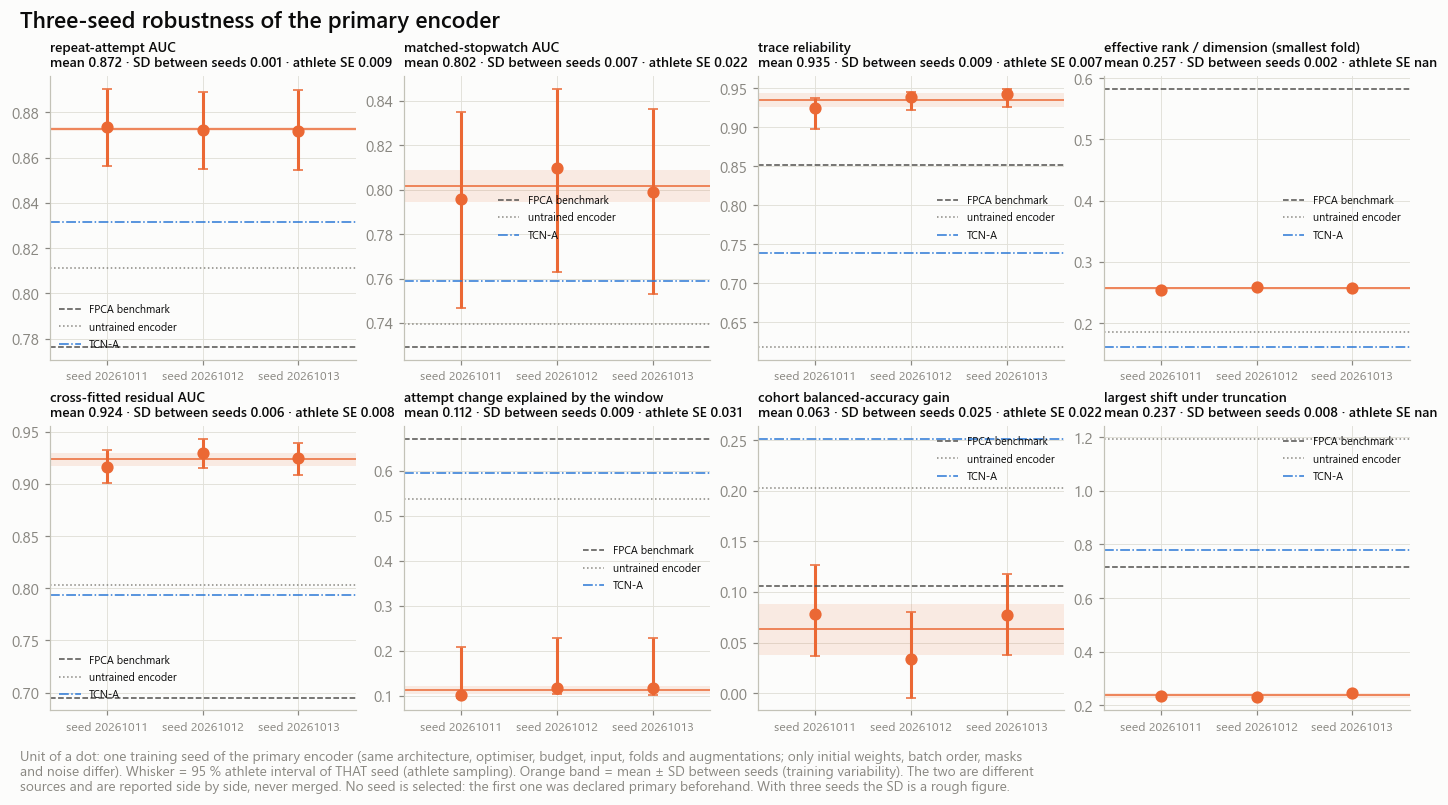

In [11]:
display(Markdown('**Estimate by training seed** (unit: confirm-role held-out athlete for AUC rows; one column per seed)'))
with pl.Config(tbl_rows=20):
    display(runs.pivot(on='method', index='metric', values='value').sort('metric'))
display(Markdown('**Spread between seeds against athlete standard error** (not merged into one interval)'))
display(seed_summary.sort('metric'))
display(Markdown('**Geometry agreement on the same held-out attempts** (unit: fold; mean over folds; 1 = identical up to a rotation)'))
display(geometry.group_by('method_a', 'method_b').agg(pl.len().alias('folds'), pl.col('n_sequences').sum(), pl.col('cka').mean(),
                                                      pl.col('cka').min().alias('cka_min'), pl.col('distance_spearman').mean(),
                                                      pl.col('neighbour_overlap').mean()).sort('method_a', 'method_b'))
display(Markdown('**Collapse diagnostics by seed** (unit: fold model; the heuristic line is a rank share of '
                 f'{ecfg.collapse_rank_share:g}; a model slightly under it and one slightly over it are not different in kind)'))
display(ev[rv.COLLAPSE.name].filter(pl.col('method').is_in(BASE_METHODS)).group_by('method').agg(
    pl.col('effective_rank').min().alias('effective_rank_min'), pl.col('effective_rank').max().alias('effective_rank_max'),
    pl.col('rank_share').min().alias('rank_share_min'), pl.col('top_eigen_share').max().alias('top_eigen_share_max'),
    pl.col('near_identical_share').max().alias('near_identical_max'), pl.col('collapsed').sum().alias('folds_flagged')).sort('method'))


def reference_values(method):
    q = fe._one(quality, method=method)
    return {k: q.get(k) for k in ('auc', 'matched_auc', 'resid_auc', 'icc_trace', 'rank_share_min', 'window_r2', 'cohort_balanced_gain',
                                  'truncation_shift_max')}


SEED_PANELS = [('auc', 'repeat-attempt AUC'), ('matched_auc', 'matched-stopwatch AUC'), ('icc_trace', 'trace reliability'),
               ('rank_share_min', 'effective rank / dimension (smallest fold)'), ('resid_auc', 'cross-fitted residual AUC'),
               ('window_r2', 'attempt change explained by the window'), ('cohort_balanced_gain', 'cohort balanced-accuracy gain'),
               ('truncation_shift_max', 'largest shift under truncation')]
REFS = {'FPCA benchmark': reference_values(FPCA_METHOD), 'untrained encoder': reference_values(RAND_METHOD),
        'TCN-A': reference_values(TCNA_METHOD)}
n_conf = str(int(quality['n_confirm'].max() or 0)) + ' confirm athletes (at most)'
store.show(rf.plot_seed_distribution(runs, seed_summary, SEED_PANELS, REFS), 'AM04B_01_three_seed_performance',
           {'runs': runs, 'summary': seed_summary}, publication=True, source='robust_seed_runs, robust_seed_summary',
           n=f'{len(SEED_METHODS)} training seeds; {n_conf}')

## 8 · Matched-stopwatch retrieval

For each held-out athlete with two embedded attempts, the impostors are the held-out athletes of the **same fold and position** whose official forty, 10-yard split, weight and height are nearest to his: at most `k_nearest`, all inside the caliper. Differences are scaled by the within-position SD among **design-role** athletes, so the rule owes nothing to the athletes it is read on. An athlete with no impostor inside the caliper is not scored, and is counted.

The statistic is the share of his matched impostors that lie farther from his attempt than his own other attempt. Next to it, the same athletes against the whole position: the difference is what matching on the stopwatch removes.

**Uncertainty.** One athlete serves as an impostor for several queries, so the comparisons are not independent. The interval to read resamples athletes as queries and as impostors together; the table also gives how often the busiest impostor is reused.

**Matching scales** (within-position SD among design-role athletes; the unit of the caliper)

variable,scale
str,f64
"""cmb_forty""",0.1591
"""cmb_ten_yd_split""",0.055181
"""cmb_combine_weight""",16.271438
"""cmb_combine_height""",1.647195


**Matched retrieval by representation** (unit: confirm-role held-out athlete with ≥ 1 matched impostor)

method,n_athletes,n_unmatched,n_comparisons,n_distinct_impostors,impostor_reuse_max,d_forty_mean,auc_matched,auc_matched_lower2,auc_matched_upper2,auc_position,matching_penalty,matching_penalty_lower,matching_penalty_upper,top1_matched,chance_top1
str,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""TCNB_A_s1""",234,31,865,306,9,0.066719,0.809687,0.762961,0.845439,0.870258,0.060572,0.043074,0.078419,0.557692,0.243875
"""TCNB_A_E16""",234,31,865,306,9,0.066719,0.805627,0.759993,0.838992,0.878558,0.072931,0.05494,0.091445,0.544872,0.243875
"""TCNB_A_s2""",234,31,865,306,9,0.066719,0.799181,0.753034,0.836185,0.867088,0.067907,0.050104,0.086333,0.549145,0.243875
"""TCNB_A""",234,31,865,306,9,0.066719,0.795762,0.746549,0.835105,0.871278,0.075516,0.055696,0.09701,0.551282,0.243875
"""SPEED2""",234,31,865,306,9,0.066719,0.768946,0.721748,0.816214,0.843148,0.074202,0.055322,0.096082,0.5,0.243875
"""TCNA_A""",234,31,865,306,9,0.066719,0.758868,0.708967,0.804739,0.827456,0.068588,0.049978,0.086906,0.527778,0.243875
"""TCNB_A_RAND""",234,31,865,306,9,0.066719,0.739708,0.687974,0.780157,0.803906,0.064198,0.044918,0.085171,0.504274,0.243875
"""FPCA_A_K2""",234,31,865,306,9,0.066719,0.729095,0.675733,0.769484,0.773464,0.044368,0.025861,0.06448,0.489316,0.243875


**Same table on all held-out athletes** (design-role athletes took part in the choice of the consistency term)

method,n_athletes,auc_matched,auc_matched_lower2,auc_matched_upper2,auc_position,matching_penalty
str,i64,f64,f64,f64,f64,f64
"""TCNB_A_s1""",331,0.797004,0.755337,0.829834,0.864265,0.067261
"""TCNB_A_E16""",331,0.795846,0.755525,0.829267,0.871851,0.076005
"""TCNB_A_s2""",331,0.789199,0.750346,0.819552,0.861544,0.072344
"""TCNB_A""",331,0.784894,0.742216,0.821355,0.864585,0.079691
"""SPEED2""",331,0.76425,0.72166,0.805173,0.836833,0.072584
"""TCNA_A""",331,0.758736,0.716421,0.79757,0.821287,0.06255
"""TCNB_A_RAND""",331,0.729532,0.68758,0.763483,0.795477,0.065945
"""FPCA_A_K2""",331,0.720519,0.672018,0.752909,0.767549,0.04703


**Paired differences of matched discrimination** (unit: confirm athlete scored by both; method − reference)

method,reference,subset,n_athletes,estimate,reference_estimate,difference,diff_lower,diff_upper
str,str,str,i64,f64,f64,f64,f64,f64
"""SPEED2""","""FPCA_A_K2""","""role:confirm""",234,0.768946,0.729095,0.03985,-0.006233,0.090861
"""TCNA_A""","""FPCA_A_K2""","""role:confirm""",234,0.758868,0.729095,0.029772,-0.001581,0.060864
"""TCNB_A""","""FPCA_A_K2""","""role:confirm""",234,0.795762,0.729095,0.066667,0.024323,0.110756
"""TCNB_A_E16""","""FPCA_A_K2""","""role:confirm""",234,0.805627,0.729095,0.076531,0.034649,0.120199
"""TCNB_A_RAND""","""FPCA_A_K2""","""role:confirm""",234,0.739708,0.729095,0.010613,-0.029574,0.052143
…,…,…,…,…,…,…,…,…
"""TCNA_A""","""TCNB_A_RAND""","""role:confirm""",234,0.758868,0.739708,0.01916,-0.017526,0.054783
"""TCNB_A""","""TCNB_A_RAND""","""role:confirm""",234,0.795762,0.739708,0.056054,0.015589,0.09491
"""TCNB_A_E16""","""TCNB_A_RAND""","""role:confirm""",234,0.805627,0.739708,0.065919,0.023856,0.10634


**How tight is the match?** (query × impostor pairs of `TCNB_A`; differences impostor − query)

pairs,match_distance_median,abs_d_forty_median_s,abs_d_forty_max_s,abs_d_ten_median_s,abs_d_weight_median_lb,abs_d_height_median
u32,f64,f64,f64,f64,f64,f64
1231,0.534013,0.06,0.21,0.02,6.0,0.75


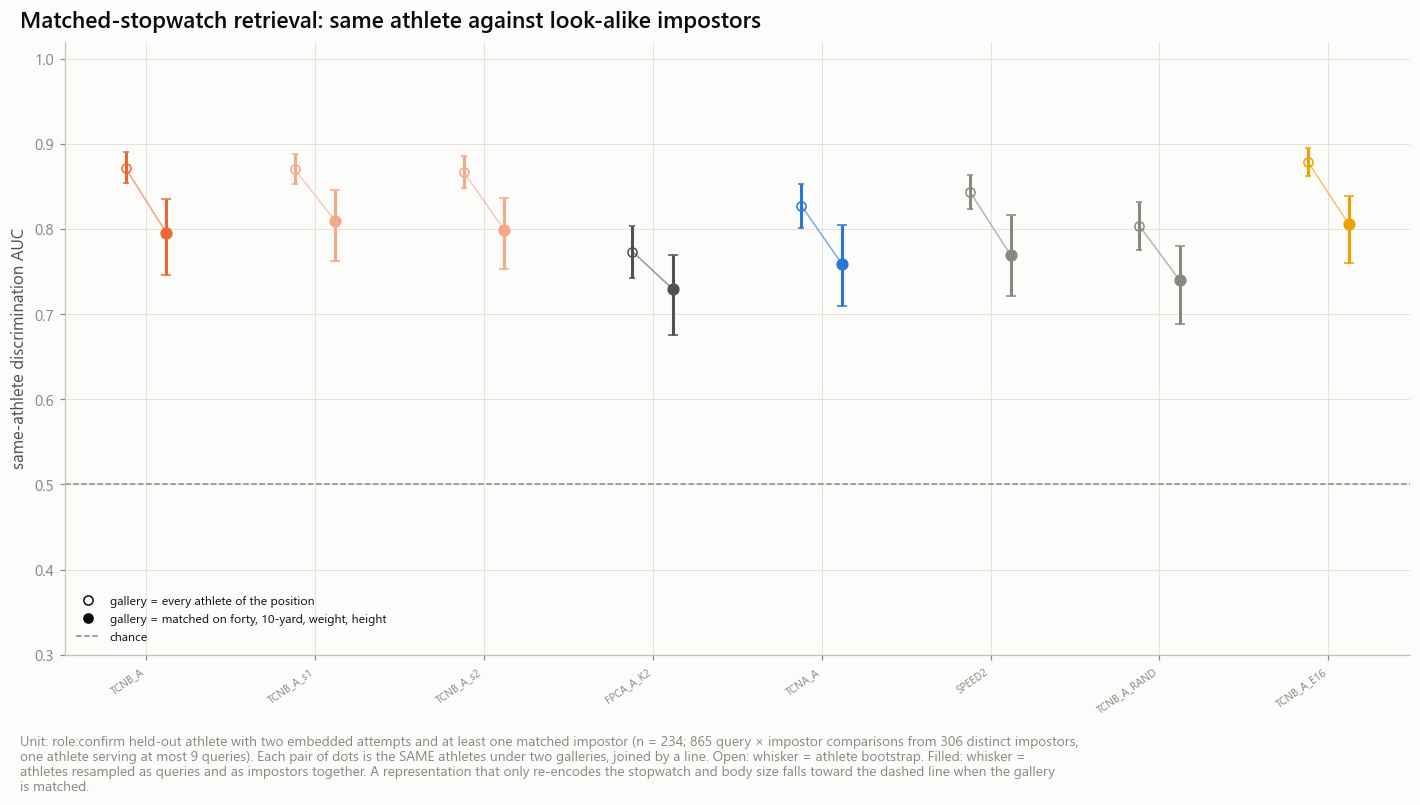

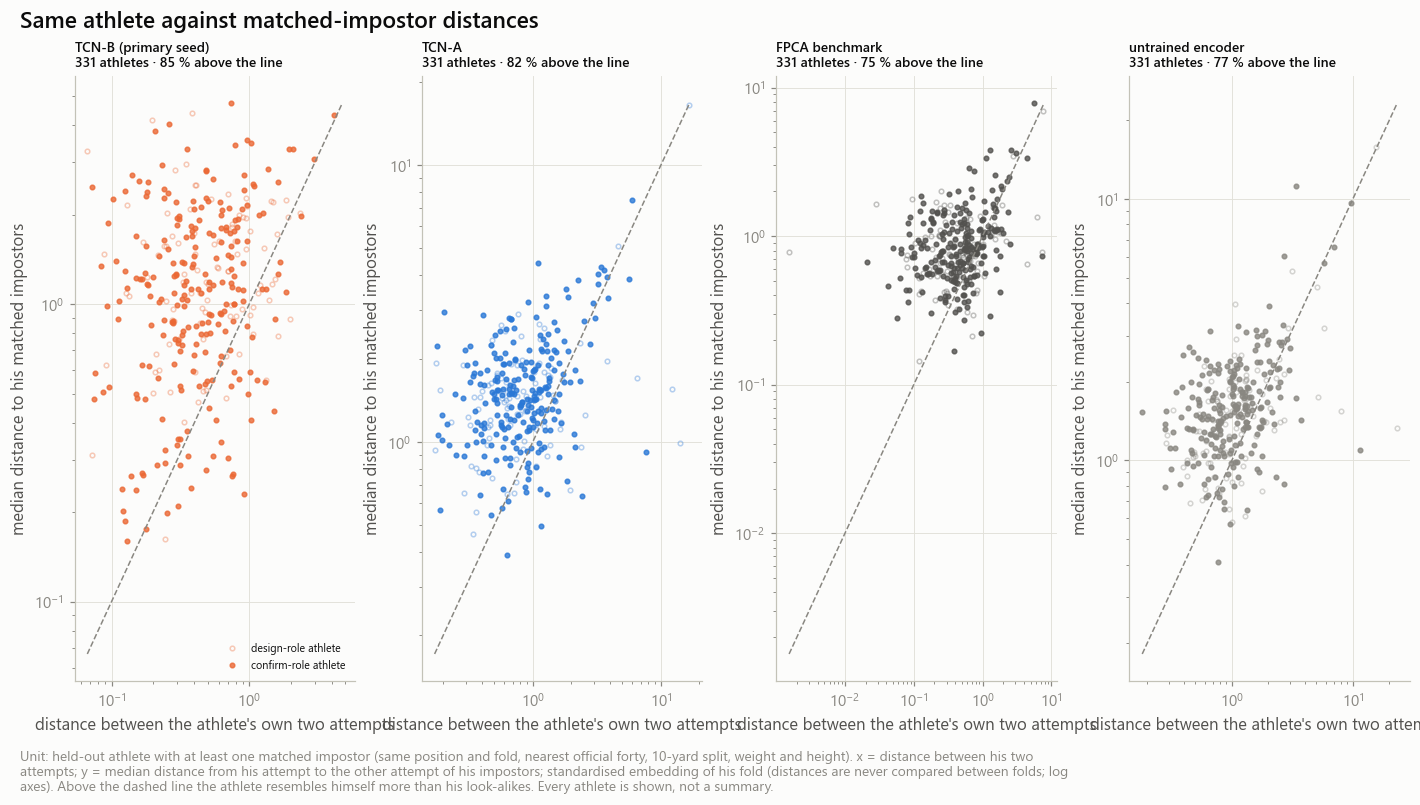

MemoryError: bad allocation

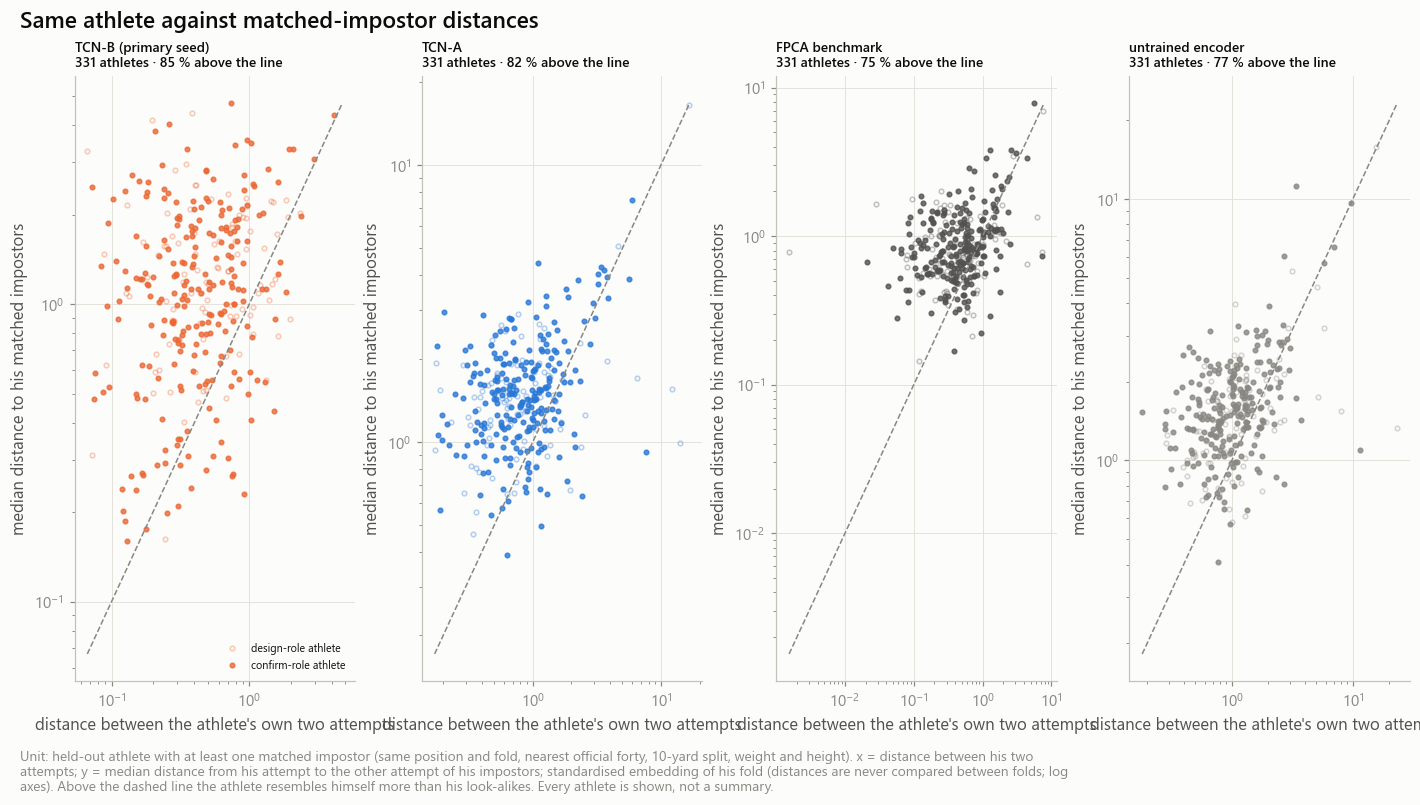

In [12]:
display(Markdown('**Matching scales** (within-position SD among design-role athletes; the unit of the caliper)'))
display(pl.DataFrame([{'variable': v, 'scale': s} for v, s in scales.items()]))
display(Markdown('**Matched retrieval by representation** (unit: confirm-role held-out athlete with ≥ 1 matched impostor)'))
display(matched_summary.filter(pl.col('method').is_in(BASE_METHODS) & (pl.col('subset') == 'role:confirm'))
        .select('method', 'n_athletes', 'n_unmatched', 'n_comparisons', 'n_distinct_impostors', 'impostor_reuse_max', 'd_forty_mean',
                'auc_matched', 'auc_matched_lower2', 'auc_matched_upper2', 'auc_position', 'matching_penalty', 'matching_penalty_lower',
                'matching_penalty_upper', 'top1_matched', 'chance_top1').sort('auc_matched', descending=True))
display(Markdown('**Same table on all held-out athletes** (design-role athletes took part in the choice of the consistency term)'))
display(matched_summary.filter(pl.col('method').is_in(BASE_METHODS) & (pl.col('subset') == 'all'))
        .select('method', 'n_athletes', 'auc_matched', 'auc_matched_lower2', 'auc_matched_upper2', 'auc_position', 'matching_penalty')
        .sort('auc_matched', descending=True))
display(Markdown('**Paired differences of matched discrimination** (unit: confirm athlete scored by both; method − reference)'))
display(matched_paired.filter(pl.col('subset') == 'role:confirm').sort('reference', 'method'))
display(Markdown(f'**How tight is the match?** (query × impostor pairs of `{PRIMARY_FROZEN}`; differences impostor − query)'))
display(match_pairs.select(pl.len().alias('pairs'), pl.col('match_distance').median().alias('match_distance_median'),
                           pl.col('d_forty').abs().median().alias('abs_d_forty_median_s'), pl.col('d_forty').abs().max().alias('abs_d_forty_max_s'),
                           pl.col('d_ten').abs().median().alias('abs_d_ten_median_s'), pl.col('d_weight').abs().median().alias('abs_d_weight_median_lb'),
                           pl.col('d_height').abs().median().alias('abs_d_height_median')))

ms = fe._one(matched_summary, method=PRIMARY_FROZEN, subset='role:confirm')
n_match = str(ms.get('n_athletes', 0)) + ' confirm athletes, ' + str(ms.get('n_comparisons', 0)) + ' matched comparisons'
store.show(rf.plot_matched_retrieval(matched_summary, quality), 'AM04B_02_matched_retrieval_tcn_vs_fpca',
           {'summary': matched_summary.filter(pl.col('method').is_in(BASE_METHODS))}, publication=True,
           source='robust_matched_summary', n=n_match)
DIST_PANELS = [(PRIMARY_FROZEN, 'TCN-B (primary seed)', 'primary'), (TCNA_METHOD, 'TCN-A', 'encoder (reconstruction only)'),
               (FPCA_METHOD, 'FPCA benchmark', 'baseline'), (RAND_METHOD, 'untrained encoder', 'control')]
store.show(rf.plot_matched_distances(matched, DIST_PANELS), 'AM04B_07_same_athlete_vs_matched_impostor_distances', publication=True,
           source='robust_matched_retrieval', n=n_match)
examples = rb.matched_examples(match_pairs, matched, PRIMARY_FROZEN, athletes, 4)
attempt_order = dict(windows.select('seq_id', 'attempt_order').iter_rows())
store.show(rf.plot_matched_examples(examples, curves[PRIMARY], attempt_order, PRIMARY, 'TCN-B, primary seed'),
           'AM04B_09_matched_stopwatch_athlete_comparisons', publication=False, source='robust_matched_pairs, sequence curves',
           n=f'{len(examples)} rule-chosen query athletes', note='examples chosen at evenly spaced quantiles of the matched AUC')

## 9 · Residualisation audit

Notebook 03 removed from every embedding dimension its linear prediction from official forty, 10-yard split, weight and height (position dummies included), **cross-fitted among the held-out athletes of a fold**, and found that TCN-B discriminated better afterwards. Removing information should not help. Two mechanisms could produce it, and they have different consequences:

- **A procedural artifact.** The covariates are constant per athlete. If ONE function is removed, the same vector leaves both attempts of an athlete and the distance between them cannot change. Cross-fitting applies a *different* fitted function to each probe fold, which adds fold-specific offsets between athletes of different probe folds — it pushes athletes apart without touching their own repeat distance.
- **Metric geometry.** The official direction carries a large share of the between-athlete variance and of the Euclidean distance. Removing it changes which dimensions dominate the distance; the remaining ones may separate athletes of a position better. That would be a property of the metric, not new information.

The audit fits the same linear model four ways and reads the discrimination under three distances, on the same athletes, the same positive pair and the same gallery:

| Mode | What it isolates |
|---|---|
| cross-fitted (notebook 03) | the published number |
| cross-fitted, official results **permuted** between athletes of a position | removes nothing real: any gain is produced by the procedure |
| fitted on the fold's **training** athletes | one function, never fitted on a held-out athlete: the fold-safe estimate |
| in sample | one function, transductive (diagnostic) |

The purpose is to explain the result, not to pick the variant with the largest AUC.

**Audit of `TCNB_A`** (unit: confirm-role held-out athlete with both official times)

covariates,mode,metric,n_athletes,auc,auc_lower,auc_upper,auc_minus_raw,diff_lower,diff_upper,auc_same_probe_fold,auc_other_probe_fold,d_same_vs_raw,d_other_median,effective_rank,norm_mean,variance_share
str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""none""","""raw""","""cosine""",265,0.864426,0.845118,0.884068,0.0,0.0,0.0,0.864426,null,1.0,0.186745,2.423489,2.709041,1.0
"""official""","""crossfit""","""cosine""",265,0.895217,0.873718,0.91505,0.03079,0.01697,0.04514,0.891864,0.897018,2.55655,1.06863,1.842111,1.574951,0.42243
"""official""","""crossfit_permuted""","""cosine""",265,0.90954,0.892119,0.927134,0.045113,0.031339,0.059004,0.900951,0.912556,1.669937,1.100009,2.35455,1.857843,0.583171
"""official""","""heldout_in_sample""","""cosine""",265,0.885846,0.863579,0.905974,0.02142,0.007365,0.035782,0.885846,null,3.369794,1.046633,1.859929,1.383083,0.322019
"""official""","""train_fit""","""cosine""",265,0.890048,0.869756,0.909106,0.025622,0.010931,0.040366,0.890048,null,3.181773,0.890095,1.860526,1.462277,0.352847
"""official_window""","""crossfit""","""cosine""",265,0.875788,0.851596,0.897995,0.011362,-0.003884,0.026773,0.859482,0.87907,3.641868,1.051934,1.80878,1.593848,0.434841
"""official_window""","""heldout_in_sample""","""cosine""",265,0.855442,0.831873,0.877002,-0.008985,-0.025131,0.006716,0.855442,null,4.863941,1.070138,1.80455,1.354811,0.310431
"""official_window""","""train_fit""","""cosine""",265,0.875782,0.854601,0.896095,0.011356,-0.005169,0.02762,0.875782,null,3.726568,0.830645,1.825847,1.453177,0.351441
"""none""","""raw""","""euclidean""",265,0.873452,0.855424,0.891027,0.0,0.0,0.0,0.873452,null,1.0,1.773908,2.423489,2.709041,1.0


**Audit of the FPCA benchmark `FPCA_A_K2`** (same athletes and gallery)

covariates,mode,metric,n_athletes,auc,auc_lower,auc_upper,auc_minus_raw,diff_lower,diff_upper,auc_same_probe_fold,auc_other_probe_fold,d_same_vs_raw,d_other_median,effective_rank,norm_mean,variance_share
str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""none""","""raw""","""euclidean""",265,0.776179,0.745457,0.807972,0.0,0.0,0.0,0.776179,null,1.0,0.995116,1.972088,1.197895,1.0
"""official""","""crossfit""","""euclidean""",265,0.695215,0.665017,0.727422,-0.080964,-0.095665,-0.067242,0.667913,0.69988,1.0,0.756727,1.113792,0.753263,0.570906
"""official""","""crossfit_permuted""","""euclidean""",265,0.800512,0.771688,0.83088,0.024333,0.01627,0.034074,0.797999,0.804408,1.0,1.144846,1.652852,0.926153,0.720097
"""official""","""heldout_in_sample""","""euclidean""",265,0.662982,0.632526,0.696462,-0.113197,-0.12951,-0.098604,0.662982,null,1.0,0.695012,1.111344,0.664612,0.472608
"""official""","""train_fit""","""euclidean""",265,0.671864,0.641717,0.705552,-0.104314,-0.118953,-0.090422,0.671864,null,1.0,0.709509,1.117072,0.688795,0.503409
"""official_window""","""crossfit""","""euclidean""",265,0.644962,0.613034,0.67748,-0.131217,-0.169386,-0.093362,0.633366,0.648762,0.816181,0.521037,1.212016,0.488468,0.269952
"""official_window""","""heldout_in_sample""","""euclidean""",265,0.616986,0.584241,0.651352,-0.159192,-0.196988,-0.120328,0.616986,null,0.781365,0.470607,1.218492,0.42859,0.160437
"""official_window""","""train_fit""","""euclidean""",265,0.628619,0.596667,0.661722,-0.14756,-0.182337,-0.110335,0.628619,null,0.775917,0.48289,1.206197,0.459028,0.232527


**Consistency with notebook 03:** cross-fitted residual AUC recomputed here 0.9167593381023635; value of the evaluation tables 0.9167593381023635 (they use the same probe folds; a small difference comes from the athletes without both official times, which the audit leaves out of the raw embedding as well).

**Rule-based reading, by representation** (for review)

- `TCNB_A` (role:confirm, n = 265): raw AUC 0.873; cross-fitted residual 0.917 (Δ 0.043 [0.035, 0.052]); cross-fitted with PERMUTED official results 0.926 (Δ 0.052); fitted on training athletes 0.903 (Δ 0.030 [0.021, 0.039]); in sample 0.901.
  - Own-repeat distance relative to raw: cross-fitted 1.000, training fit 1.000 (1 = unchanged, as expected when one vector is removed from both attempts); cross-fitted gallery under the same fitted function 0.902 against another function 0.919; residual variance share 0.422; effective rank raw 2.423 → 1.842.
  - Reading (rule-based, for review): the increase also appears when the official results are permuted, so it is produced by the cross-fitting procedure (different fitted functions for different athletes), not by removing stopwatch information.
- `TCNB_A_s1` (role:confirm, n = 265): raw AUC 0.872; cross-fitted residual 0.930 (Δ 0.057 [0.048, 0.068]); cross-fitted with PERMUTED official results 0.931 (Δ 0.058); fitted on training athletes 0.914 (Δ 0.041 [0.031, 0.052]); in sample 0.913.
  - Own-repeat distance relative to raw: cross-fitted 1.000, training fit 1.000 (1 = unchanged, as expected when one vector is removed from both attempts); cross-fitted gallery under the same fitted function 0.915 against another function 0.933; residual variance share 0.390; effective rank raw 2.352 → 1.813.
  - Reading (rule-based, for review): the increase also appears when the official results are permuted, so it is produced by the cross-fitting procedure (different fitted functions for different athletes), not by removing stopwatch information.
- `TCNB_A_s2` (role:confirm, n = 265): raw AUC 0.872; cross-fitted residual 0.925 (Δ 0.053 [0.043, 0.063]); cross-fitted with PERMUTED official results 0.928 (Δ 0.056); fitted on training athletes 0.904 (Δ 0.032 [0.022, 0.041]); in sample 0.901.
  - Own-repeat distance relative to raw: cross-fitted 1.000, training fit 1.000 (1 = unchanged, as expected when one vector is removed from both attempts); cross-fitted gallery under the same fitted function 0.907 against another function 0.928; residual variance share 0.366; effective rank raw 2.188 → 1.617.
  - Reading (rule-based, for review): the increase also appears when the official results are permuted, so it is produced by the cross-fitting procedure (different fitted functions for different athletes), not by removing stopwatch information.
- `TCNA_A` (role:confirm, n = 265): raw AUC 0.832; cross-fitted residual 0.794 (Δ -0.038 [-0.052, -0.025]); cross-fitted with PERMUTED official results 0.869 (Δ 0.037); fitted on training athletes 0.756 (Δ -0.075 [-0.090, -0.063]); in sample 0.748.
  - Own-repeat distance relative to raw: cross-fitted 1.000, training fit 1.000 (1 = unchanged, as expected when one vector is removed from both attempts); cross-fitted gallery under the same fitted function 0.781 against another function 0.796; residual variance share 0.356; effective rank raw 2.223 → 2.743.
  - Reading (rule-based, for review): the cross-fitted residual does not exceed the raw embedding on these athletes: nothing to explain.
- `FPCA_A_K2` (role:confirm, n = 265): raw AUC 0.776; cross-fitted residual 0.695 (Δ -0.081 [-0.096, -0.067]); cross-fitted with PERMUTED official results 0.801 (Δ 0.024); fitted on training athletes 0.672 (Δ -0.104 [-0.119, -0.090]); in sample 0.663.
  - Own-repeat distance relative to raw: cross-fitted 1.000, training fit 1.000 (1 = unchanged, as expected when one vector is removed from both attempts); cross-fitted gallery under the same fitted function 0.668 against another function 0.700; residual variance share 0.571; effective rank raw 1.972 → 1.114.
  - Reading (rule-based, for review): the cross-fitted residual does not exceed the raw embedding on these athletes: nothing to explain.
- `TCNB_A_RAND` (role:confirm, n = 265): raw AUC 0.811; cross-fitted residual 0.803 (Δ -0.009 [-0.020, 0.003]); cross-fitted with PERMUTED official results 0.855 (Δ 0.043); fitted on training athletes 0.758 (Δ -0.053 [-0.064, -0.042]); in sample 0.756.
  - Own-repeat distance relative to raw: cross-fitted 1.000, training fit 1.000 (1 = unchanged, as expected when one vector is removed from both attempts); cross-fitted gallery under the same fitted function 0.778 against another function 0.808; residual variance share 0.482; effective rank raw 2.688 → 2.780.
  - Reading (rule-based, for review): the cross-fitted residual does not exceed the raw embedding on these athletes: nothing to explain.

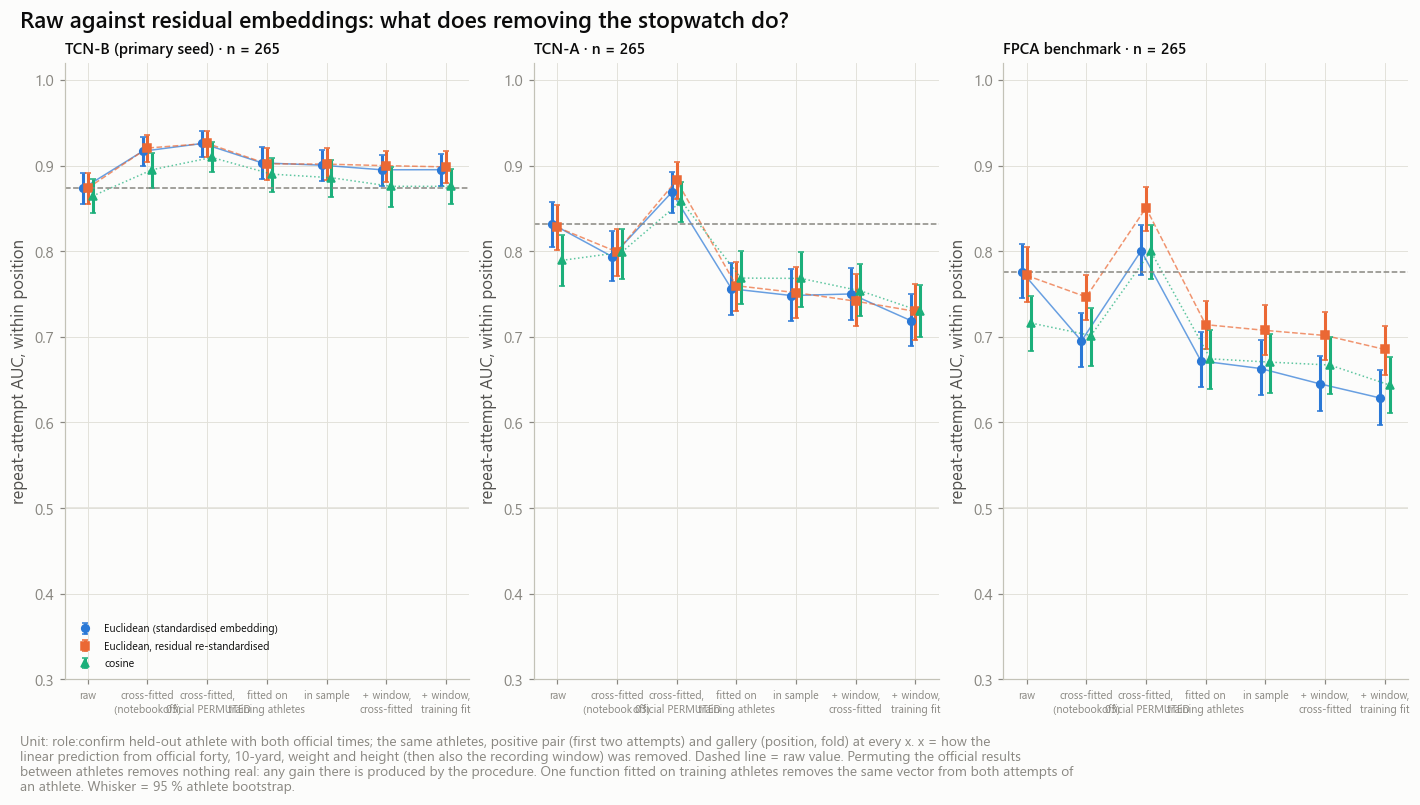

In [13]:
def audit_view(method, subset='role:confirm'):
    return (audit.filter((pl.col('method') == method) & (pl.col('subset') == subset))
            .select('covariates', 'mode', 'metric', 'n_athletes', 'auc', 'auc_lower', 'auc_upper', 'auc_minus_raw', 'diff_lower', 'diff_upper',
                    'auc_same_probe_fold', 'auc_other_probe_fold', 'd_same_vs_raw', 'd_other_median', 'effective_rank', 'norm_mean',
                    'variance_share').sort('metric', 'covariates', 'mode'))


display(Markdown(f'**Audit of `{PRIMARY_FROZEN}`** (unit: confirm-role held-out athlete with both official times)'))
with pl.Config(tbl_rows=40):
    display(audit_view(PRIMARY_FROZEN))
display(Markdown(f'**Audit of the FPCA benchmark `{FPCA_METHOD}`** (same athletes and gallery)'))
with pl.Config(tbl_rows=40):
    display(audit_view(FPCA_METHOD).filter(pl.col('metric') == 'euclidean'))
check = fe._one(audit, method=PRIMARY_FROZEN, covariates='official', mode='crossfit', metric='euclidean', subset='role:confirm')
nb03_value = fe._one(summary, method=PRIMARY_FROZEN).get('resid_auc')
display(Markdown(f'**Consistency with notebook 03:** cross-fitted residual AUC recomputed here {check.get("auc")}; value of the evaluation '
                 f'tables {nb03_value} (they use the same probe folds; a small difference comes from the athletes without both official '
                 'times, which the audit leaves out of the raw embedding as well).'))
display(Markdown('**Rule-based reading, by representation** (for review)'))
display(Markdown('\n'.join(rb.audit_reading(audit, m, ecfg) for m in [*SEED_METHODS, TCNA_METHOD, FPCA_METHOD, RAND_METHOD])))

AUDIT_PANELS = [(PRIMARY_FROZEN, 'TCN-B (primary seed)'), (TCNA_METHOD, 'TCN-A'), (FPCA_METHOD, 'FPCA benchmark')]
store.show(rf.plot_residual_audit(audit, AUDIT_PANELS), 'AM04B_03_raw_vs_residual_embedding_retrieval',
           {'audit': audit.filter(pl.col('subset') == 'role:confirm')}, publication=True, source='robust_residualisation_audit', n=n_conf)

## 10 · Effective dimensionality

The embedding of every seed is projected on the first 2, 4 and 8 principal axes of the **training** embeddings of its fold; 8 is a rotation of the original and reproduces it exactly. The projections go through the same evaluation. Axes are never matched between seeds or folds: the statistics are computed inside a fold and are rotation-invariant, so no alignment is needed and none is attempted.

The rule for the optional compact candidate was fixed beforehand: the smallest k whose confirm-athlete AUC is within the practical margin of the 8-dimensional one (lower bound of the paired interval above minus the margin) **for every seed**. No NFL value enters it.

**Evidence by dimension** (unit: confirm-role athlete for AUC columns; references: FPCA at its own K, the 16-d sensitivity model)

method,base_method,training_seed,k,auc,auc_lower,auc_upper,matched_auc,matched_auc_lower,matched_auc_upper,resid_auc,icc_trace,effective_rank,forty_partial_r2,window_r2,cohort_gain
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""FPCA_A_K2""",null,2,0.776179,0.744975,0.806438,0.729095,0.675733,0.769484,0.695215,0.851733,1.208136,0.909382,0.670966,0.100478
"""TCNB_A|pc2""","""TCNB_A""",20261011,2,0.858517,0.840603,0.876277,0.774679,0.723122,0.816889,0.910291,0.942319,1.974453,0.814011,0.104291,0.004785
"""TCNB_A|pc4""","""TCNB_A""",20261011,4,0.871409,0.854396,0.888388,0.793839,0.744016,0.833001,0.914654,0.927119,2.389041,0.872795,0.097645,0.052632
"""TCNB_A|pc8""","""TCNB_A""",20261011,8,0.873452,0.856494,0.890426,0.795762,0.746549,0.835105,0.916759,0.924947,2.424519,0.896853,0.102067,0.148325
"""TCNB_A_E16""","""TCNB_A_E16""",null,16,0.88011,0.86419,0.896704,0.805627,0.759993,0.838992,0.935111,0.928466,3.405363,0.899847,0.094051,0.126794
"""TCNB_A_s1|pc2""","""TCNB_A_s1""",20261012,2,0.865612,0.848298,0.883432,0.797863,0.756215,0.836381,0.921476,0.945683,1.971446,0.796418,0.097912,0.014354
"""TCNB_A_s1|pc4""","""TCNB_A_s1""",20261012,4,0.869992,0.853287,0.886803,0.805413,0.758804,0.84196,0.928999,0.939772,2.316531,0.874536,0.109452,0.026316
"""TCNB_A_s1|pc8""","""TCNB_A_s1""",20261012,8,0.872254,0.855181,0.888864,0.809687,0.762961,0.845439,0.929558,0.937719,2.352241,0.888504,0.117699,0.15311
"""TCNB_A_s2|pc2""","""TCNB_A_s2""",20261013,2,0.865426,0.847956,0.882372,0.794017,0.750731,0.831745,0.912774,0.949048,1.968746,0.835223,0.092417,-0.002392


**Projection against the full 8-dimensional embedding, paired on athletes** (confirm athletes, AUC)

method,reference,n_athletes,estimate,reference_estimate,difference,diff_lower,diff_upper
str,str,i64,f64,f64,f64,f64,f64
"""TCNB_A_s1|pc2""","""TCNB_A_s1|pc8""",265,0.865612,0.872254,-0.006642,-0.011775,-0.001756
"""TCNB_A_s1|pc4""","""TCNB_A_s1|pc8""",265,0.869992,0.872254,-0.002262,-0.004314,-0.000349
"""TCNB_A_s2|pc2""","""TCNB_A_s2|pc8""",265,0.865426,0.871748,-0.006322,-0.012042,-0.000509
"""TCNB_A_s2|pc4""","""TCNB_A_s2|pc8""",265,0.870807,0.871748,-0.000942,-0.003186,0.001554
"""TCNB_A|pc2""","""TCNB_A|pc8""",265,0.858517,0.873452,-0.014935,-0.021411,-0.008662
"""TCNB_A|pc4""","""TCNB_A|pc8""",265,0.871409,0.873452,-0.002043,-0.004515,0.000253


**Compact projection (pre-declared rule, margin 0.02):** k = 4: paired AUC difference from the 8-dimensional embedding has a lower bound above −0.02 for all 3 seed(s).

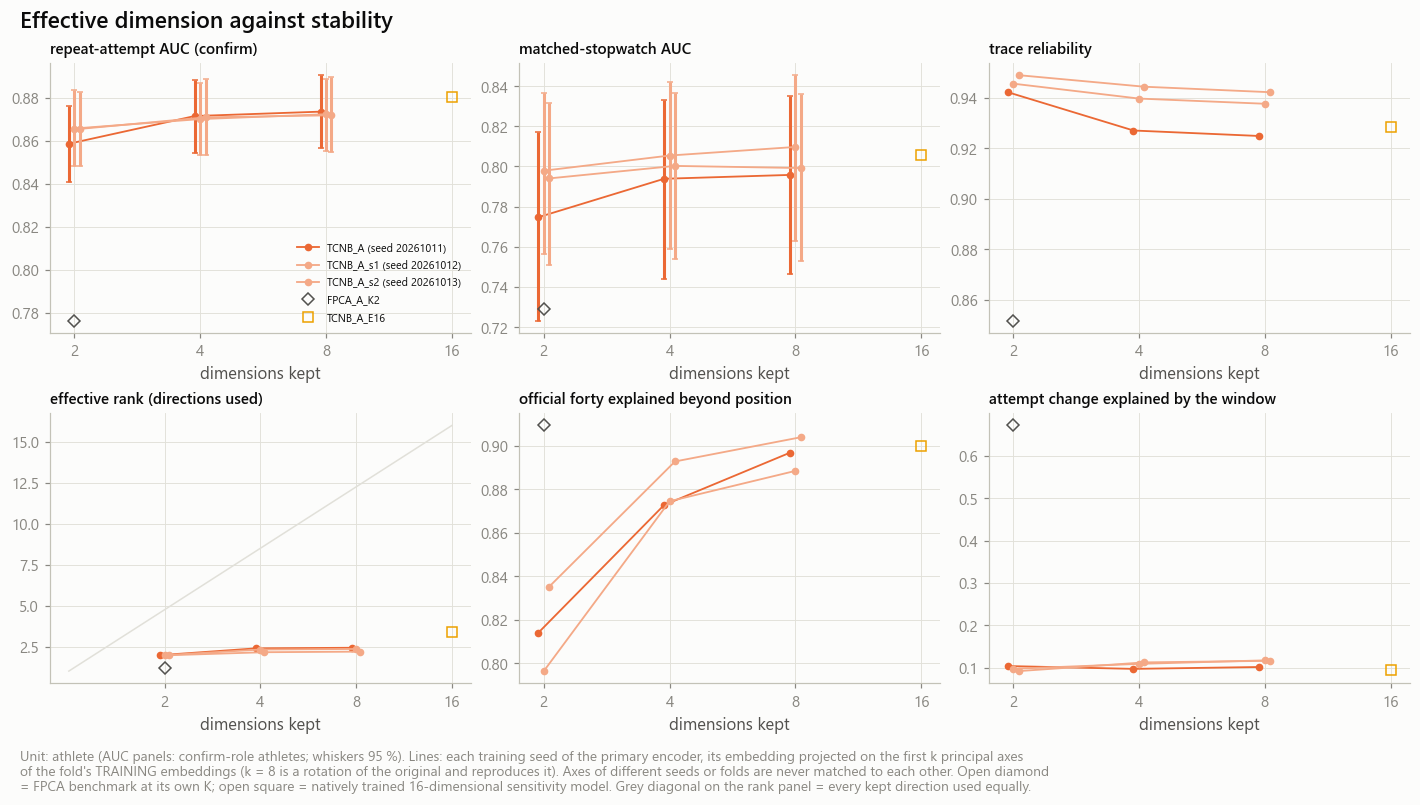

In [14]:
display(Markdown('**Evidence by dimension** (unit: confirm-role athlete for AUC columns; references: FPCA at its own K, the 16-d sensitivity model)'))
with pl.Config(tbl_rows=30):
    display(dims.sort('base_method', 'k'))
display(Markdown(f'**Projection against the full {FULL_DIM}-dimensional embedding, paired on athletes** (confirm athletes, AUC)'))
display(paired_dims.filter((pl.col('subset') == 'role:confirm') & (pl.col('metric') == 'auc') & (pl.col('space') == 'standardised'))
        .select('method', 'reference', 'n_athletes', 'estimate', 'reference_estimate', 'difference', 'diff_lower', 'diff_upper').sort('method'))
display(Markdown(f'**Compact projection (pre-declared rule, margin {ecfg.margin_auc:g}):** {compact[1]}.'))
store.show(rf.plot_dimension_stability(dims, PRIMARY_FROZEN), 'AM04B_04_effective_dimension_vs_stability', {'dimensions': dims},
           publication=True, source='robust_dimension_stability', n=n_conf)

## 11 · Acquisition and cohort robustness

- **Draft cohort.** A ridge probe from the athlete embedding to the cohort, fitted and scored on disjoint athletes, read with the class counts, the majority share, chance and **balanced** accuracy, against the same probe with position alone. Plain accuracy is misleading when cohorts are unequal.
- **Truncated early and late frames.** The same held-out attempt embedded with its first or last 15 % and 30 % of recorded points hidden. Points are only hidden; nothing before the first or after the last recorded frame is invented, and a view covering less than half of the support is not embedded.
- **First recorded speed, recording duration, noise level, tracking quality.** Cross-fitted probes from one attempt's embedding to a property of its recording, and the share of the attempt-to-attempt change explained by the change of the window.
- **Leave-one-cohort-out** (sensitivity). The encoder and the functional PCA are fitted on the other cohorts and applied to the held-out one, against the within-fold value of the same cohort with a same-cohort gallery. Sample sizes per cohort are small; read direction, not decimals.

**Draft-cohort probe** (unit: athlete; gain = balanced accuracy − the same probe with position alone)

method,protocol,n_athletes,class_counts,majority_share,chance,accuracy,balanced_accuracy,bal_lower,bal_upper,baseline_balanced_accuracy,gain_balanced,gain_lower,gain_upper
str,str,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""heldout_crossfit""",418,"""2023: 138; 2024: 147; 2025: 133""",0.351675,0.333333,0.308612,0.308649,0.26583,0.354518,0.202351,0.106298,0.057597,0.146156
"""SPEED2""","""heldout_crossfit""",418,"""2023: 138; 2024: 147; 2025: 133""",0.351675,0.333333,0.191388,0.189376,0.153224,0.225243,0.202351,-0.012975,-0.043121,0.018487
"""TCNA_A""","""heldout_crossfit""",418,"""2023: 138; 2024: 147; 2025: 133""",0.351675,0.333333,0.452153,0.453266,0.404051,0.494705,0.202351,0.250915,0.199812,0.304791
"""TCNB_A""","""heldout_crossfit""",418,"""2023: 138; 2024: 147; 2025: 133""",0.351675,0.333333,0.284689,0.281132,0.239242,0.323702,0.202351,0.078781,0.036874,0.126286
"""TCNB_A_E16""","""heldout_crossfit""",418,"""2023: 138; 2024: 147; 2025: 133""",0.351675,0.333333,0.334928,0.331912,0.291234,0.374524,0.202351,0.12956,0.08138,0.182284
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""TCNB_A""","""train_to_heldout""",418,"""2023: 138; 2024: 147; 2025: 133""",0.351675,0.333333,0.483254,0.479677,0.429222,0.524269,0.367241,0.112437,0.054243,0.165736
"""TCNB_A_E16""","""train_to_heldout""",418,"""2023: 138; 2024: 147; 2025: 133""",0.351675,0.333333,0.478469,0.477073,0.432021,0.521048,0.367241,0.109832,0.056607,0.16196
"""TCNB_A_RAND""","""train_to_heldout""",418,"""2023: 138; 2024: 147; 2025: 133""",0.351675,0.333333,0.504785,0.503233,0.454482,0.552324,0.367241,0.135992,0.080316,0.188219


**Repeatability inside each draft cohort** (unit: held-out athlete of the cohort; gallery = position, any cohort)

method,cohort:2023,cohort:2024,cohort:2025
str,f64,f64,f64
"""FPCA_A_K2""",0.836519,0.702431,0.779447
"""SPEED2""",0.838435,0.842911,0.851277
"""TCNA_A""",0.886954,0.750592,0.84239
"""TCNB_A""",0.884205,0.846649,0.875409
"""TCNB_A_E16""",0.879804,0.861843,0.884611
"""TCNB_A_RAND""",0.840309,0.766389,0.80863
"""TCNB_A_s1""",0.869883,0.852369,0.882557
"""TCNB_A_s2""",0.879353,0.844199,0.878412


**Recording variables from one attempt** (unit: attempt, athletes resampled; gain = partial R² or AUC beyond position)

...

method,space,n_athletes,r2_trace,r2_lower,r2_upper
str,str,i64,f64,f64,f64
"""SPEED2""","""standardised""",375,0.077325,0.055854,0.18401
"""TCNB_A_E16""","""standardised""",375,0.094051,0.100575,0.190478
"""TCNB_A""","""standardised""",375,0.102067,0.096202,0.207994
"""TCNB_A_s2""","""standardised""",375,0.116642,0.101496,0.227593
"""TCNB_A_s1""","""standardised""",375,0.117699,0.103864,0.229713
"""TCNB_A_RAND""","""standardised""",375,0.537847,0.394907,0.763821
"""TCNA_A""","""standardised""",375,0.594742,0.500441,0.773644
"""FPCA_A_K2""","""standardised""",375,0.670966,0.609497,0.810042


**Controlled truncation** (unit: held-out athlete; shift relative to the median distance between athletes)

method,view,n_athletes,n_sequences,relative_shift,shift_lower,shift_upper,auc,auc_lower,auc_upper,auc_full,top1,top1_full
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""head_15""",418,793,0.255177,0.23472,0.275134,0.741686,0.715207,0.769951,0.780956,0.261333,0.309333
"""TCNA_A""","""head_15""",418,793,0.561609,0.530699,0.593415,0.768383,0.740753,0.795493,0.838359,0.274667,0.378667
"""TCNB_A""","""head_15""",418,793,0.222267,0.209742,0.235167,0.842366,0.822892,0.860623,0.869129,0.32,0.378667
"""TCNB_A_E16""","""head_15""",418,793,0.191075,0.181284,0.200023,0.872743,0.856945,0.888273,0.879348,0.357333,0.394667
"""TCNB_A_RAND""","""head_15""",418,793,0.79651,0.759185,0.837161,0.6931,0.663363,0.723511,0.813506,0.205333,0.346667
…,…,…,…,…,…,…,…,…,…,…,…,…
"""TCNB_A""","""tail_30""",418,793,0.226804,0.216078,0.238648,0.804759,0.786773,0.822288,0.869129,0.221333,0.378667
"""TCNB_A_E16""","""tail_30""",418,793,0.280477,0.268609,0.292026,0.789839,0.76845,0.81071,0.879348,0.226667,0.394667
"""TCNB_A_RAND""","""tail_30""",418,793,0.990803,0.949346,1.029724,0.66058,0.630659,0.689771,0.813506,0.144,0.346667


**Leave-one-cohort-out** (unit: held-out athlete of the cohort with two attempts; same-cohort gallery in both protocols)

method,cohort,protocol,n_athletes,gallery_mean,auc,auc_lower,auc_upper
str,str,str,i64,f64,f64,f64,f64
"""FPCA_A_K2""","""2023""","""leave_cohort_out""",124,26.403226,0.835582,0.802445,0.867073
"""FPCA_A_K2""","""2023""","""within_fold""",123,4.666667,0.831911,0.793477,0.868433
"""FPCA_A_K2""","""2024""","""leave_cohort_out""",122,26.885246,0.691731,0.640285,0.739383
"""FPCA_A_K2""","""2024""","""within_fold""",120,4.833333,0.721419,0.667535,0.771083
"""FPCA_A_K2""","""2025""","""leave_cohort_out""",129,26.341085,0.748721,0.704496,0.790378
…,…,…,…,…,…,…,…
"""TCNB_A""","""2023""","""within_fold""",123,4.666667,0.898374,0.867205,0.923244
"""TCNB_A""","""2024""","""leave_cohort_out""",122,26.885246,0.840987,0.809223,0.872029
"""TCNB_A""","""2024""","""within_fold""",120,4.833333,0.853403,0.82138,0.883136


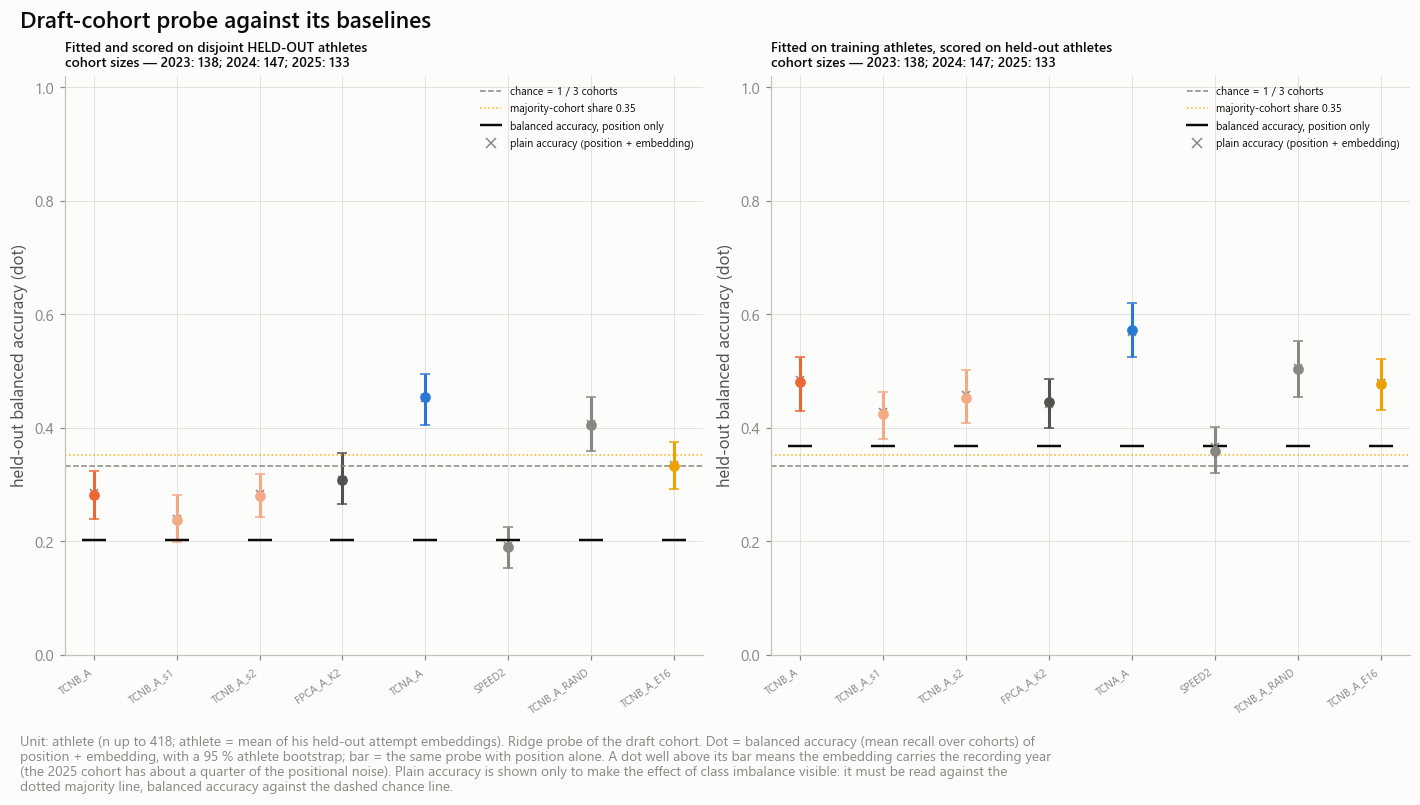

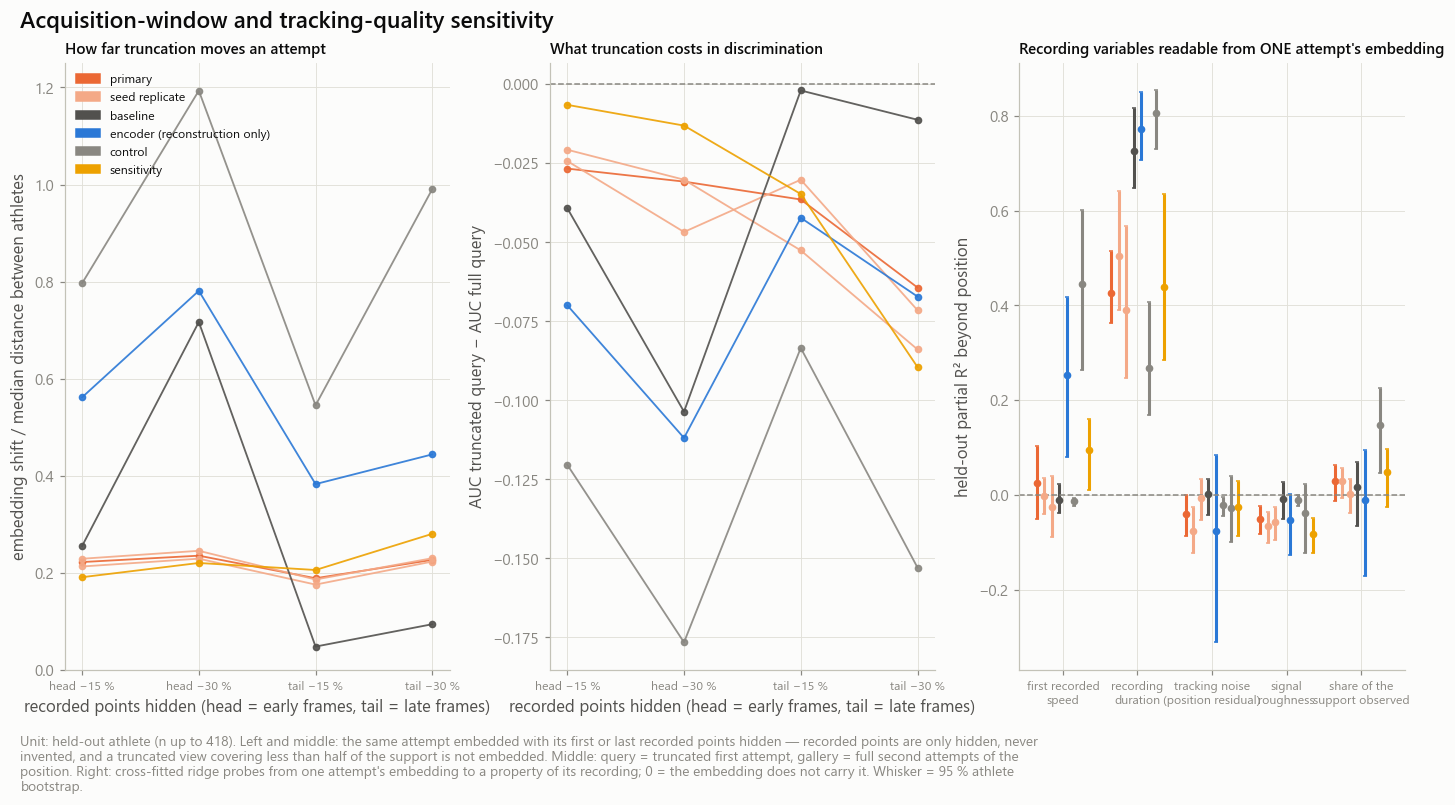

In [15]:
display(Markdown('**Draft-cohort probe** (unit: athlete; gain = balanced accuracy − the same probe with position alone)'))
with pl.Config(fmt_str_lengths=60):
    display(cohort.select('method', 'protocol', 'n_athletes', 'class_counts', 'majority_share', 'chance', 'accuracy', 'balanced_accuracy',
                          'bal_lower', 'bal_upper', 'baseline_balanced_accuracy', 'gain_balanced', 'gain_lower', 'gain_upper')
            .sort('protocol', 'method'))
display(Markdown('**Repeatability inside each draft cohort** (unit: held-out athlete of the cohort; gallery = position, any cohort)'))
display(ev[rv.REPEAT.name].filter(pl.col('method').is_in(BASE_METHODS) & (pl.col('space') == 'standardised')
                                  & (pl.col('scope') == 'within_position') & pl.col('subset').str.starts_with('cohort:'))
        .pivot(on='subset', index='method', values='auc').sort('method'))
display(Markdown('**Recording variables from one attempt** (unit: attempt, athletes resampled; gain = partial R² or AUC beyond position)'))
with pl.Config(tbl_rows=90):
    display(ev[rv.PROBES.name].filter(pl.col('method').is_in([*SEED_METHODS, FPCA_METHOD, RAND_METHOD]) & (pl.col('level') == 'attempt'))
            .select('method', 'target', 'metric', 'n_athletes', 'baseline', 'value', 'gain', 'gain_lower', 'gain_upper').sort('target', 'method'))
display(Markdown('**Attempt-to-attempt change explained by the change of the recording window** (unit: athlete with two attempts)'))
display(ev[rv.WINDOW.name].filter(pl.col('method').is_in(BASE_METHODS) & (pl.col('space') == 'standardised')).sort('r2_trace'))
display(Markdown('**Controlled truncation** (unit: held-out athlete; shift relative to the median distance between athletes)'))
display(ev[rv.TRUNC.name].filter(pl.col('method').is_in(BASE_METHODS)).sort('view', 'method'))
if loco.height:
    display(Markdown('**Leave-one-cohort-out** (unit: held-out athlete of the cohort with two attempts; same-cohort gallery in both protocols)'))
    display(loco.sort('method', 'cohort', 'protocol'))
else:
    display(Markdown('**Leave-one-cohort-out:** not run, or no cohort large enough to hold out in this run mode.'))

n_ath = str(int(cohort['n_athletes'].max() or 0)) + ' athletes (at most)' if cohort.height else 'no athlete'
store.show(rf.plot_cohort_probe(cohort, quality), 'AM04B_05_cohort_probe_vs_baseline', {'cohort': cohort}, publication=True,
           source='robust_cohort_probe', n=n_ath)
store.show(rf.plot_acquisition(ev[rv.TRUNC.name], ev[rv.PROBES.name], quality), 'AM04B_06_acquisition_window_sensitivity',
           {'truncation': ev[rv.TRUNC.name].filter(pl.col('method').is_in(BASE_METHODS))}, publication=True,
           source='robust_truncation_stability, robust_probes', n=n_ath)

## 12 · Representation quality, side by side

One row per representation. The rule-based reading of notebook 03 (A / B / C / D against the functional PCA of the same input) is repeated for every seed as a consistency check; it is a screening label, and its collapse rule is a single heuristic line.

**Evidence by representation** (AUC columns: confirm-role held-out athletes)

method,kind,embedding_dim,n_confirm,auc,auc_lower,auc_upper,matched_auc,matched_auc_lower,matched_auc_upper,resid_auc,icc_trace,forty_partial_r2,window_r2,cohort_balanced_gain,truncation_shift_max,rank_share_min,collapsed
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
"""FPCA_A_K2""","""baseline""",2,265,0.776179,0.744975,0.806438,0.729095,0.675733,0.769484,0.695215,0.851733,0.909382,0.670966,0.106298,0.71679,0.582469,false
"""SPEED2""","""control""",2,265,0.850623,0.83462,0.866758,0.768946,0.721748,0.816214,0.712219,0.948454,0.858584,0.077325,-0.012975,null,0.50042,false
"""TCNB_A_RAND""","""control""",8,265,0.811417,0.785999,0.836215,0.739708,0.687974,0.780157,0.802709,0.617795,0.883499,0.537847,0.202273,1.1934,0.185548,true
"""TCNA_A""","""encoder (reconstruction only)""",8,265,0.831626,0.805972,0.857686,0.758868,0.708967,0.804739,0.793806,0.738614,0.90307,0.594742,0.250915,0.781062,0.16079,true
"""TCNB_A""","""primary""",8,265,0.873452,0.856494,0.890426,0.795762,0.746549,0.835105,0.916759,0.925027,0.889904,0.102067,0.078781,0.23543,0.254536,false
"""TCNB_A_s1""","""seed replicate""",8,265,0.872254,0.855181,0.888864,0.809687,0.762961,0.845439,0.929558,0.938224,0.886526,0.117699,0.034252,0.229254,0.258884,false
"""TCNB_A_s2""","""seed replicate""",8,265,0.871748,0.85446,0.8897,0.799181,0.753034,0.836185,0.92465,0.942143,0.899211,0.116642,0.076934,0.245489,0.25791,false
"""TCNB_A_E16""","""sensitivity""",16,265,0.88011,0.86419,0.896704,0.805627,0.759993,0.838992,0.935111,0.928466,0.899847,0.094051,0.12956,0.280477,0.193265,true


**Rule-based reading of notebook 03, repeated for every seed** (against the FPCA benchmark; for review)

method,verdict,repeatability,nonredundant,nuisance,reconstruction,detail
str,str,str,str,str,str,str
"""TCNA_A""","""C negative (collapsed)""","""better""","""better""","""increased""","""worse""","""Δ AUC +0.055 [+0.035, +0.076]; Δ residual AUC +0.099 [+0.075, +0.123]; residual AUC lower bound +0.766; Δ RMSE +0.106 [+0.097, +0.115]; window / cohort excess over the reference -0.076, +0.144"""
"""TCNB_A""","""A strong positive""","""better""","""better""","""controlled""","""worse""","""Δ AUC +0.097 [+0.065, +0.128]; Δ residual AUC +0.222 [+0.188, +0.255]; residual AUC lower bound +0.901; Δ RMSE +0.135 [+0.122, +0.148]; window / cohort excess over the reference -0.569, -0.024"""
"""TCNB_A_RAND""","""C negative (collapsed)""","""better""","""better""","""increased""","""worse""","""Δ AUC +0.035 [+0.007, +0.064]; Δ residual AUC +0.107 [+0.074, +0.141]; residual AUC lower bound +0.775; Δ RMSE +0.536 [+0.506, +0.564]; window / cohort excess over the reference -0.133, +0.098"""
"""TCNB_A_s1""","""A strong positive""","""better""","""better""","""controlled""","""worse""","""Δ AUC +0.096 [+0.063, +0.127]; Δ residual AUC +0.234 [+0.201, +0.266]; residual AUC lower bound +0.916; Δ RMSE +0.140 [+0.126, +0.154]; window / cohort excess over the reference -0.553, -0.069"""
"""TCNB_A_s2""","""A strong positive""","""better""","""better""","""controlled""","""worse""","""Δ AUC +0.096 [+0.065, +0.126]; Δ residual AUC +0.229 [+0.197, +0.262]; residual AUC lower bound +0.909; Δ RMSE +0.137 [+0.125, +0.150]; window / cohort excess over the reference -0.554, -0.026"""


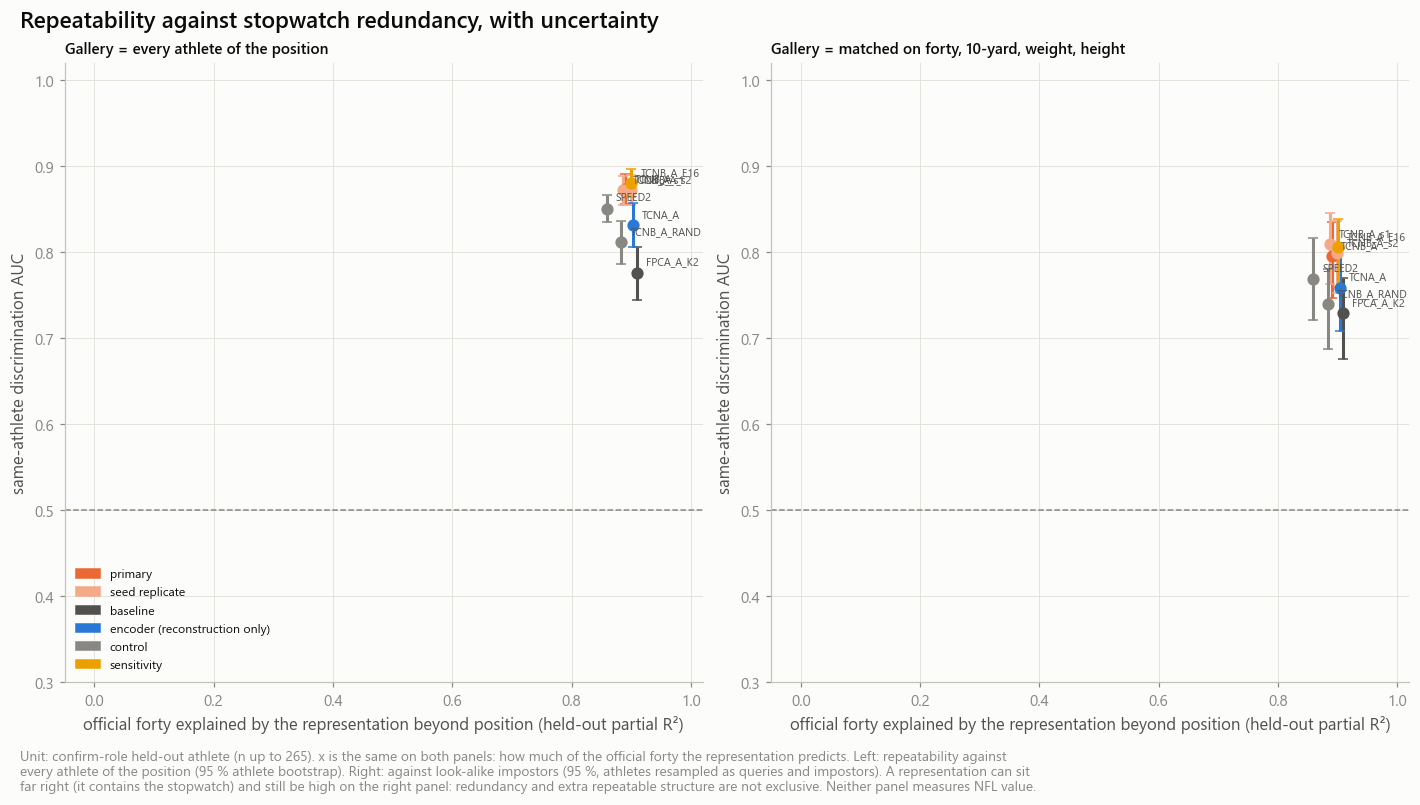

In [16]:
display(Markdown('**Evidence by representation** (AUC columns: confirm-role held-out athletes)'))
with pl.Config(tbl_rows=40):
    display(quality.filter(pl.col('kind') != 'projection')
            .select('method', 'kind', 'embedding_dim', 'n_confirm', 'auc', 'auc_lower', 'auc_upper', 'matched_auc', 'matched_auc_lower',
                    'matched_auc_upper', 'resid_auc', 'icc_trace', 'forty_partial_r2', 'window_r2', 'cohort_balanced_gain',
                    'truncation_shift_max', 'rank_share_min', 'collapsed').sort('kind', 'method'))
display(Markdown('**Rule-based reading of notebook 03, repeated for every seed** (against the FPCA benchmark; for review)'))
with pl.Config(fmt_str_lengths=220):
    display(verdict.filter(pl.col('method').is_in([*SEED_METHODS, TCNA_METHOD, RAND_METHOD]))
            .select('method', 'verdict', 'repeatability', 'nonredundant', 'nuisance', 'reconstruction', 'detail'))
store.show(rf.plot_reliability_redundancy(quality), 'AM04B_08_reliability_vs_redundancy_with_uncertainty',
           {'quality': quality.filter(pl.col('kind') != 'projection')}, publication=True, source='robust_representation_quality', n=n_conf)

## 13 · Atlas freeze — the shortlist

Seven pre-declared slots, each filled by a rule from saved Combine evidence. A slot whose rule nothing meets stays in the table, unselected, with the reason. No NFL value is an input to any rule.

| Slot | Rule |
|---|---|
| C1 traditional baseline | official forty and 10-yard split, with weight and height: the comparator, carried by definition |
| C2 reliable speed control | the tracked speed feature with the highest reliability lower bound among those graded Strong or Provisional in 04A |
| C3 interpretable acceleration | the acceleration feature (sustained or direct) with the highest reliability lower bound, graded Strong or Provisional |
| C4 sprint-curve parameter | a fitted parameter of the existing model, not extrapolated and not redundant, graded Strong or Provisional |
| C5 functional PCA | the benchmark K scores of input A as one vector |
| C6 TCN-B 8-d | the **pre-declared primary seed**, never the best seed; dropped only if it is `not_ready` |
| C7 compact projection | the smallest training-fitted projection that keeps the discrimination for every seed (optional) |

The eight coordinates of the encoder are one candidate, not eight measurements. Features left out are listed in `transfer_exploratory_registry` for exploratory use only.

**Immutability.** `transfer_candidates_v1` is written once per run mode. A later run that would produce a different table reports the difference and keeps the frozen one, unless `REFREEZE_SHORTLIST` is set. A smoke run writes its own copy under `_sample`, which is a wiring check and not the shortlist.

01:36:50 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_FREEZE] transfer_exploratory_registry: 30 rows → warehouse/gold/advanced_movement/atlas/transfer_exploratory_registry.parquet
01:36:50 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_FREEZE] transfer_candidates_v1: 7 rows → warehouse/gold/advanced_movement/atlas/transfer_candidates_v1.parquet


**Primary encoder readiness (Combine evidence only): `ready_for_transfer_test`.** Every criterion is met for every seed.

**`transfer_candidates_v1`: frozen now.** Configuration hash `827d48ea8b764832`. 6 of 7 slots selected.

candidate_id,group,role,selected,readiness,features,unit_dimensionality
str,str,str,bool,str,str,str
"""C1_traditional_baseline""","""traditional Combine baseline""","""reference""",true,"""reference""","""F1.official.cmb_forty;F1.official.cmb_ten_yd_split;F1.official.cmb_combine_weight;F1.official.cmb_combine_height""","""s, s, lb, in · 4 values per athlete"""
"""C2_speed_control""","""reliable speed control""","""control""",true,"""ready_for_transfer_test""","""F2.forty.p95_speed""","""yd/s · 1 value per athlete (mean of attempts)"""
"""C3_acceleration""","""physically interpretable acceleration""","""candidate""",true,"""carry_with_caveat""","""F6.forty.time_v4_to_v8_s""","""s · 1 value per athlete (mean of attempts)"""
"""C4_sprint_parameter""","""sprint-curve parameter""","""candidate""",false,"""not_ready""","""""",null
"""C5_fpca""","""functional PCA benchmark""","""learned benchmark""",true,"""carry_with_caveat""","""FPCA_A_K2""","""K scores per attempt; athlete = mean"""
"""C6_tcn_b_8d""","""TCN-B 8-d embedding""","""candidate""",true,"""ready_for_transfer_test""","""TCNB_A""","""8-d vector per attempt; athlete = mean of his out-of-fold attempt embeddings"""
"""C7_tcn_compact""","""compact TCN projection""","""candidate (optional)""",true,"""ready_for_transfer_test""","""TCNB_A|pc4""","""4-d vector per attempt"""


candidate_id,sample_eligibility,measurement_reliability,nuisance_sensitivity,stopwatch_redundancy
str,str,str,str,str
"""C1_traditional_baseline""","""share of tracked athletes with a value — official forty-yard dash 1.00; official 10-yard split 1.00; weight 1.00; height 1.00""","""not estimable here: one official value per athlete""","""not applicable (hand or electronic timing, not the tracking recording)""","""this IS the stopwatch: every other family is judged by what it adds to it"""
"""C2_speed_control""","""418 of 418 tracked athletes with a value; 375 with a repeat""","""within-position ICC 0.95 [0.94, 0.96]; SEM 0.089 yd/s; rank agreement of two attempts 0.93""","""window R² 0.04 [0.01, 0.11]; cohort R² 0.00; ICC under the strictest quality filter 0.95 → robust""","""max |ρ| 0.89 [0.86, 0.91]; stopwatch R² 0.87; reliable share not explained 0.10 → redundant"""
"""C3_acceleration""","""418 of 418 tracked athletes with a value; 375 with a repeat""","""within-position ICC 0.82 [0.78, 0.86]; SEM 0.076 s; rank agreement of two attempts 0.73""","""window R² 0.09 [0.03, 0.28]; cohort R² 0.04; ICC under the strictest quality filter 0.85 → uncertain""","""max |ρ| 0.65 [0.59, 0.70]; stopwatch R² 0.65; reliable share not explained 0.25 → beyond_stopwatch"""
"""C4_sprint_parameter""",null,null,null,null
"""C5_fpca""","""265 confirm-role athletes with a repeat (read-out); every tracked athlete is embedded out of fold""","""repeat-attempt AUC 0.776 [0.745, 0.806]; trace ICC 0.852; effective rank share 0.58""","""window R² 0.67 [0.61, 0.81]; cohort balanced-accuracy gain 0.11 [0.06, 0.15]; largest shift under truncation 0.72""","""official forty explained beyond position 0.91; matched-stopwatch AUC 0.729 [0.676, 0.769]"""
"""C6_tcn_b_8d""","""265 confirm-role athletes with a repeat (read-out); every tracked athlete is embedded out of fold""","""repeat-attempt AUC 0.873 [0.856, 0.890]; over 3 seeds 0.872 ± 0.001 (SD between seeds); trace ICC 0.925; effective rank share 0.25""","""window R² 0.10 [0.10, 0.21]; cohort balanced-accuracy gain 0.08 [0.04, 0.13]; largest shift under truncation 0.24""","""official forty explained beyond position 0.89; matched-stopwatch AUC 0.796 [0.747, 0.835]; over 3 seeds 0.802 ± 0.007 (SD between seeds)"""
"""C7_tcn_compact""","""265 confirm-role athletes with a repeat (read-out); every tracked athlete is embedded out of fold""","""repeat-attempt AUC 0.871 [0.854, 0.888]; trace ICC 0.927; effective rank share 0.51""","""window R² 0.10 [0.09, 0.20]; cohort balanced-accuracy gain n/a [n/a, n/a]; largest shift under truncation 0.21""","""official forty explained beyond position 0.87; matched-stopwatch AUC 0.794 [0.744, 0.833]"""


candidate_id,selection_rationale,known_limitations,artifact_paths
str,str,str,str
"""C1_traditional_baseline""","""comparator of the transfer study; carried by definition, not by a screening rule""","""official timing protocol differs from the tracked recording; height may be missing or not numeric""","""warehouse/gold/advanced_movement/atlas/atlas_athlete_features.parquet"""
"""C2_speed_control""","""tracked speed feature with the highest reliability lower bound among those graded Strong or Provisional; grade Strong (high reliability and no measured acquisition dependence)""","""expected to be redundant with the official forty: it controls for 'tracking measures the stopwatch again'""","""warehouse/gold/advanced_movement/atlas/atlas_athlete_features.parquet"""
"""C3_acceleration""","""interpretable acceleration feature (sustained or direct) with the highest reliability lower bound, graded Strong or Provisional; grade Provisional (reliability high, acquisition uncertain)""","""measured on the recorded part of the run only: the first steps are not in the recording; repeatability differs by position and cohort""","""warehouse/gold/advanced_movement/atlas/atlas_athlete_features.parquet"""
"""C4_sprint_parameter""","""no feature met the rule (fitted parameter of the existing exponential sprint model, not extrapolated and not redundant, with the highest reliability lower bound); best exploratory alternative: F4.forty.model_vmax (Provisional)""","""defined only for attempts whose fit passed its flags; a good curve fit does not make the parameter identifiable; the recording starts after the first movement""","""warehouse/gold/advanced_movement/atlas/atlas_athlete_features.parquet"""
"""C5_fpca""","""low-complexity learned benchmark every encoder is compared with; carried by design""","""its first component is largely the stopwatch; later components are less repeatable or follow the recording window""","""warehouse/gold/advanced_movement/fpca_ref_attempt_embeddings.parquet ; artifacts/models/advanced_movement/fpca"""
"""C6_tcn_b_8d""","""primary representation of notebook 03, frozen at its PRE-DECLARED first training seed; the other seeds are robustness replicates on which the transfer result must also be reported""","""coordinates are not comparable between folds or seeds; linear residualisation leaves any nonlinear function of the official times; no physical interpretation; NFL value untested""","""warehouse/gold/advanced_movement/atlas/robust_athlete_embeddings.parquet ; warehouse/gold/advanced_movement/tcn_b_attempt_embeddings.parquet ; artifacts/models/advanced_movement/tcn ; artifacts/models/advanced_movement/atlas/tcn"""
"""C7_tcn_compact""","""k = 4: paired AUC difference from the 8-dimensional embedding has a lower bound above −0.02 for all 3 seed(s)""","""a projection of C6: not an independent candidate; axes are fold-specific""","""warehouse/gold/advanced_movement/atlas/robust_athlete_embeddings.parquet ; warehouse/gold/advanced_movement/tcn_b_attempt_embeddings.parquet ; artifacts/models/advanced_movement/tcn ; artifacts/models/advanced_movement/atlas/tcn"""


**Exploratory registry** (30 candidates not carried into the confirmatory comparison)

feature_id,family,grade,transfer_eligibility,stopwatch_relation,reason
str,str,str,str,str,str
"""F4.forty.model_a0""","""F4""","""Exploratory""","""exploratory_only""","""low_correlation_only""","""reliability uncertain, acquisition sensitive"""
"""F4.forty.model_a_at_ref""","""F4""","""Exploratory""","""exploratory_only""","""low_correlation_only""","""reliability uncertain, acquisition sensitive"""
"""F4.forty.model_tau_s""","""F4""","""Exploratory""","""exploratory_only""","""low_correlation_only""","""reliability uncertain, acquisition sensitive"""
"""F5.fpca.A_alt_origin_at_ref_speed.pc2""","""F5""","""Exploratory""","""exploratory_only""","""low_correlation_only""","""reliability uncertain, acquisition uncertain"""
"""F5.fpca.B_accel_by_speed.pc1""","""F5""","""Exploratory""","""exploratory_only""","""low_correlation_only""","""reliability uncertain, acquisition uncertain"""
"""F5.fpca.B_alt_boundary_kept.pc1""","""F5""","""Exploratory""","""exploratory_only""","""low_correlation_only""","""reliability uncertain, acquisition uncertain"""
"""F5.fpca.B_alt_boundary_kept.pc2""","""F5""","""Exploratory""","""exploratory_only""","""low_correlation_only""","""reliability uncertain, acquisition uncertain"""
"""F5.fpca.C_alt_origin_at_ref_speed.pc2""","""F5""","""Exploratory""","""exploratory_only""","""low_correlation_only""","""reliability uncertain, acquisition uncertain"""
"""F5.fpca.C_speed_by_time.pc1""","""F5""","""Exploratory""","""exploratory_only""","""uncertain""","""reliability uncertain, acquisition sensitive"""


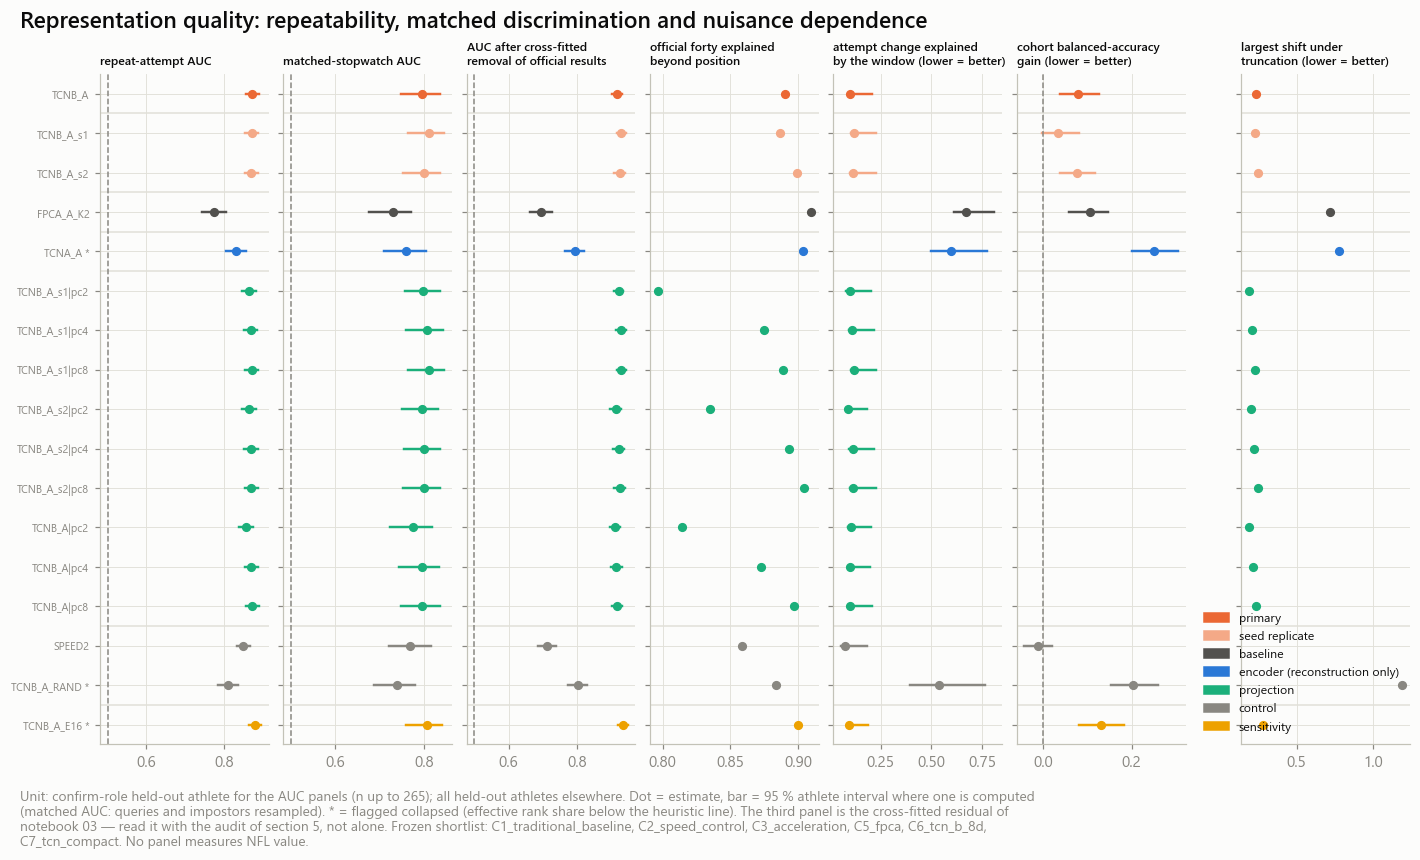

In [17]:
control_diff = fe._one(matched_paired, method=PRIMARY_FROZEN, reference=RAND_METHOD, subset='role:confirm')
FREEZE_CONFIG = {'atlas': c.params(), 'eval': ecfg.params(), 'matching': mc.params(), 'tcn': tcfg_b.params(),
                 'training_seeds': [int(s) for s in TRAINING_SEEDS], 'embedding_dims': [int(k) for k in EMBEDDING_DIMS],
                 'fpca_key': FPCA_KEY, 'seed': controls.seed, 'primary': PRIMARY_FROZEN}
config_hash = stable_hash(FREEZE_CONFIG)
preprocessing = (f'advanced_movement {amc.VERSION} · fpca {fp.FPCA_VERSION} · tcn {tcn.TCN_VERSION} · atlas {at.ATLAS_VERSION} · '
                 f'robust {rb.ROBUST_VERSION} · fpca fit key {FPCA_KEY} · split repeat {REPEATS[0]}')
rel = cfg.paths.rel
PATHS = {'athlete_features': rel(store.parquet(at.ATHLETE_VALUES)),
         'fpca': rel(up.parquet(rv.named(rv.EMBEDDINGS, 'fpca_ref'))) + ' ; ' + rel(up.models_dir / 'fpca'),
         'tcn': ' ; '.join([rel(store.parquet(rv.named(rv.ATHLETE_EMB, 'robust'))), rel(up.parquet(rv.named(rv.EMBEDDINGS, 'tcn_b'))),
                            rel(up.models_dir / 'tcn'), rel(store.models_dir / 'tcn')])}
shortlist_now, exploratory = rb.build_shortlist(status, chars, dictionary, quality, seed_summary, PRIMARY_FROZEN, list(SEED_METHODS),
                                                FPCA_METHOD, compact, control_diff, c, config_hash, preprocessing, PATHS)
shortlist, freeze_state = rb.freeze_shortlist(store, shortlist_now, exploratory, {'config': FREEZE_CONFIG, 'config_hash': config_hash,
                                                                                  'run_mode': controls.run_mode},
                                              refreeze=REFREEZE_SHORTLIST or controls.smoke)

readiness, failed = rb.encoder_readiness(quality, list(SEED_METHODS), control_diff, c)
display(Markdown(f'**Primary encoder readiness (Combine evidence only): `{readiness}`.** '
                 + ('Criteria not met: ' + '; '.join(failed) + '.' if failed else 'Every criterion is met for every seed.')))
display(Markdown(f'**`transfer_candidates_v1`: {freeze_state}.** Configuration hash `{config_hash}`. '
                 f'{shortlist.filter(pl.col("selected")).height} of {shortlist.height} slots selected.'))
with pl.Config(tbl_rows=20, fmt_str_lengths=400, tbl_width_chars=260):
    display(shortlist.select('candidate_id', 'group', 'role', 'selected', 'readiness', 'features', 'unit_dimensionality'))
    display(shortlist.select('candidate_id', 'sample_eligibility', 'measurement_reliability', 'nuisance_sensitivity', 'stopwatch_redundancy'))
    display(shortlist.select('candidate_id', 'selection_rationale', 'known_limitations', 'artifact_paths'))
display(Markdown(f'**Exploratory registry** ({exploratory.height} candidates not carried into the confirmatory comparison)'))
with pl.Config(tbl_rows=60, fmt_str_lengths=120):
    display(exploratory.sort('grade', 'feature_id'))

store.show(rf.plot_quality_summary(quality, shortlist), 'AM04B_10_representation_quality_summary', {'quality': quality},
           publication=True, source='robust_representation_quality, transfer_candidates_v1', n=n_conf)

## 14 · Saved outputs

In [18]:
ROBUST_TABLES = [*rb.prefixed_contracts('robust', EVAL_C), *rb.prefixed_contracts('robust', rv.GATE_CONTRACTS), *MATCH_C, rb.RESID_AUDIT,
                 rb.COHORT_PROBE, rb.SEED_RUNS, rb.SEED_SUMMARY, rb.GEOMETRY, rb.DIMS, DIMS_PAIRED, rb.QUALITY, rb.LOCO, rb.SHORTLIST,
                 rb.EXPLORATORY]
listing = pl.DataFrame([{'name': t.name, 'kind': t.kind, 'grain': t.area, 'key': ', '.join(t.key),
                         'parquet': rel(store.parquet(t)), 'written': store.exists(t)} for t in ROBUST_TABLES])
with pl.Config(tbl_rows=50, fmt_str_lengths=110):
    display(listing)
figure_files = sorted(p.name for p in store.figures_dir.glob('AM04B_*.png'))
model_dir = store.models_dir / 'tcn'
model_files = sorted(p.name for p in model_dir.glob('*.pt')) if model_dir.is_dir() else []
display(Markdown(f'**Figures** ({rel(store.figures_dir)}): ' + (', '.join(figure_files) or 'none (SAVE_FIGURES is off)')))
display(Markdown(f'**Checkpoints of the new seeds** ({rel(model_dir)}): {len(model_files)} file(s). The checkpoints of notebook 03 '
                 f'({rel(up.models_dir / "tcn")}) are read, never written.'))
if controls.save_tables:
    store.write_json('robust_manifest', {
        'notebook': '04b_tcn_robustness_and_shortlist', 'seed': controls.seed, 'device': device, 'config_hash': config_hash,
        'question': 'Does the TCN-B result of notebook 03 survive training seeds, matched-stopwatch impostors, a residualisation audit, '
                    'fewer dimensions, acquisition and cohort checks and null controls?',
        'scientific_status': 'technical check only (smoke run)' if controls.smoke else 'full-population run',
        'nfl_outcomes_read': False, 'encoder_configuration_source': config_source, 'primary_seed_reused_from_notebook_03': bool(REUSE_FIRST),
        'training_seeds': SEED_METHODS, 'primary_method': PRIMARY_FROZEN, 'config': FREEZE_CONFIG, 'methods': methods['method'].to_list(),
        'kinds': KINDS, 'matching_scales': scales, 'compact_dimension': {'k': compact[0], 'rule': compact[1]},
        'readiness': readiness, 'criteria_not_met': failed, 'shortlist_state': freeze_state,
        'selected': shortlist.filter(pl.col('selected'))['candidate_id'].to_list(),
        'tables': [t.name for t in ROBUST_TABLES], 'figures': figure_files, 'checkpoints': model_files,
        'validation': {r['check']: r['status'] for r in validation_report.iter_rows(named=True)}})

name,kind,grain,key,parquet,written
str,str,str,str,str,bool
"""robust_methods""","""table""","""method""","""method""","""warehouse/gold/advanced_movement/atlas/robust_methods.parquet""",true
"""robust_athlete_embeddings""","""dataset""","""method × split repeat × athlete × dimension""","""method, repeat, nfl_id, dim""","""warehouse/gold/advanced_movement/atlas/robust_athlete_embeddings.parquet""",true
"""robust_pair_statistics""","""dataset""","""method × space × scope × athlete""","""method, space, scope, repeat, nfl_id""","""warehouse/gold/advanced_movement/atlas/robust_pair_statistics.parquet""",true
"""robust_repeatability""","""table""","""method × space × scope × subset""","""method, space, scope, subset""","""warehouse/gold/advanced_movement/atlas/robust_repeatability.parquet""",true
"""robust_paired_comparisons""","""table""","""method × reference × subset × metric""","""method, reference, space, scope, subset, metric""","""warehouse/gold/advanced_movement/atlas/robust_paired_comparisons.parquet""",true
"""robust_trace_reliability""","""table""","""method × space""","""method, space""","""warehouse/gold/advanced_movement/atlas/robust_trace_reliability.parquet""",true
"""robust_collapse""","""table""","""method × fold""","""method, repeat, outer_fold""","""warehouse/gold/advanced_movement/atlas/robust_collapse.parquet""",true
"""robust_covariance_spectrum""","""table""","""method × fold × index""","""method, repeat, outer_fold, index""","""warehouse/gold/advanced_movement/atlas/robust_covariance_spectrum.parquet""",true
"""robust_probes""","""table""","""method × protocol × target""","""method, protocol, target""","""warehouse/gold/advanced_movement/atlas/robust_probes.parquet""",true


**Figures** (reports/figures/advanced_movement/atlas): AM04B_01_three_seed_performance.png, AM04B_02_matched_retrieval_tcn_vs_fpca.png, AM04B_03_raw_vs_residual_embedding_retrieval.png, AM04B_04_effective_dimension_vs_stability.png, AM04B_05_cohort_probe_vs_baseline.png, AM04B_06_acquisition_window_sensitivity.png, AM04B_08_reliability_vs_redundancy_with_uncertainty.png, AM04B_10_representation_quality_summary.png

**Checkpoints of the new seeds** (artifacts/models/advanced_movement/atlas/tcn): 10 file(s). The checkpoints of notebook 03 (artifacts/models/advanced_movement/tcn) are read, never written.

## 15 · Conclusions

Generated from the saved tables of this run. A smoke run states that it must not be interpreted.

In [19]:
COMPARED = {'FPCA benchmark': FPCA_METHOD, 'TCN-A': TCNA_METHOD, 'untrained encoder': RAND_METHOD, 'tracked top speed': SPEED_METHOD}
conclusions = rb.conclusions_markdown(quality, seed_summary, matched_paired, audit, shortlist, freeze_state, PRIMARY_FROZEN, COMPARED,
                                      compact, ecfg, controls.run_mode)
if controls.save_tables:
    store.tables_dir.mkdir(parents=True, exist_ok=True)
    (store.tables_dir / 'robust_conclusions.md').write_text(conclusions, encoding='utf-8')
display(Markdown(conclusions))

_Generated from the `robust_*` tables and `transfer_candidates_v1` of this run (`RUN_MODE = 'full'`). Read-out: confirm-role held-out athletes, within position, 95 % athlete intervals. Labels are heuristic._

**RQ5 — does the TCN-B result survive training seeds and matched impostors?**
- repeat-attempt AUC: mean 0.872 over 3 seed(s), SD between seeds 0.001, range [0.872, 0.873]; athlete standard error 0.009.
- matched-stopwatch AUC: mean 0.802 over 3 seed(s), SD between seeds 0.007, range [0.796, 0.810]; athlete standard error 0.022.
- trace reliability: mean 0.935 over 3 seed(s), SD between seeds 0.009, range [0.925, 0.942]; athlete standard error 0.007.
- effective rank / dimension (smallest fold): mean 0.257 over 3 seed(s), SD between seeds 0.002, range [0.255, 0.259]; athlete standard error n/a.
- cross-fitted residual AUC: mean 0.924 over 3 seed(s), SD between seeds 0.006, range [0.917, 0.930]; athlete standard error 0.008.
- attempt change explained by the window: mean 0.112 over 3 seed(s), SD between seeds 0.009, range [0.102, 0.118]; athlete standard error 0.031.
- cohort balanced-accuracy gain: mean 0.063 over 3 seed(s), SD between seeds 0.025, range [0.034, 0.079]; athlete standard error 0.022.
- Matched discrimination, `TCNB_A` − FPCA benchmark: +0.067 [0.024, 0.111] on 234 confirm athletes with a matched impostor.
- Matched discrimination, `TCNB_A` − TCN-A: +0.037 [-0.001, 0.077] on 234 confirm athletes with a matched impostor.
- Matched discrimination, `TCNB_A` − untrained encoder: +0.056 [0.016, 0.095] on 234 confirm athletes with a matched impostor.
- Matched discrimination, `TCNB_A` − tracked top speed: +0.027 [-0.006, 0.059] on 234 confirm athletes with a matched impostor.
- Collapse flag (effective rank share below 0.25): 0 of 3 seed(s).

**Why did the residual AUC of notebook 03 exceed the raw AUC?**
- `TCNB_A` (role:confirm, n = 265): raw AUC 0.873; cross-fitted residual 0.917 (Δ 0.043 [0.035, 0.052]); cross-fitted with PERMUTED official results 0.926 (Δ 0.052); fitted on training athletes 0.903 (Δ 0.030 [0.021, 0.039]); in sample 0.901.
  - Own-repeat distance relative to raw: cross-fitted 1.000, training fit 1.000 (1 = unchanged, as expected when one vector is removed from both attempts); cross-fitted gallery under the same fitted function 0.902 against another function 0.919; residual variance share 0.422; effective rank raw 2.423 → 1.842.
  - Reading (rule-based, for review): the increase also appears when the official results are permuted, so it is produced by the cross-fitting procedure (different fitted functions for different athletes), not by removing stopwatch information.

**Effective dimension.** k = 4: paired AUC difference from the 8-dimensional embedding has a lower bound above −0.02 for all 3 seed(s).

**RQ6 — frozen shortlist** (frozen now)
- `C1_traditional_baseline` · traditional Combine baseline: **selected** (reference) — F1.official.cmb_forty;F1.official.cmb_ten_yd_split;F1.official.cmb_combine_weight;F1.official.cmb_combine_height. comparator of the transfer study; carried by definition, not by a screening rule
- `C2_speed_control` · reliable speed control: **selected** (ready_for_transfer_test) — F2.forty.p95_speed. tracked speed feature with the highest reliability lower bound among those graded Strong or Provisional; grade Strong (high reliability and no measured acquisition dependence)
- `C3_acceleration` · physically interpretable acceleration: **selected** (carry_with_caveat) — F6.forty.time_v4_to_v8_s. interpretable acceleration feature (sustained or direct) with the highest reliability lower bound, graded Strong or Provisional; grade Provisional (reliability high, acquisition uncertain)
- `C4_sprint_parameter` · sprint-curve parameter: **not selected** (not_ready) — no feature. no feature met the rule (fitted parameter of the existing exponential sprint model, not extrapolated and not redundant, with the highest reliability lower bound); best exploratory alternative: F4.forty.model_vmax (Provisional)
- `C5_fpca` · functional PCA benchmark: **selected** (carry_with_caveat) — FPCA_A_K2. low-complexity learned benchmark every encoder is compared with; carried by design
- `C6_tcn_b_8d` · TCN-B 8-d embedding: **selected** (ready_for_transfer_test) — TCNB_A. primary representation of notebook 03, frozen at its PRE-DECLARED first training seed; the other seeds are robustness replicates on which the transfer result must also be reported
- `C7_tcn_compact` · compact TCN projection: **selected** (ready_for_transfer_test) — TCNB_A|pc4. k = 4: paired AUC difference from the 8-dimensional embedding has a lower bound above −0.02 for all 3 seed(s)

**What is and is not established.** A selected family exists, is measurable on the stated athletes, and has the repeatability, stopwatch relation and nuisance dependence written in its row. `ready_for_transfer_test` means the Combine-side evidence justifies TESTING it against NFL movement; it does not mean it predicts anything. **Demonstrated NFL predictive value: NOT TESTED in this milestone** — no NFL outcome was read, and a same-athlete retrieval metric does not measure football ability. The eight coordinates of the encoder are one vector, not eight validated physiological measurements.

## 16 · Review and next decision

After the FULL run, read sections 7 to 13 and record the decision below. The next milestone is **NFL movement outcome reliability**: before any Combine representation is compared with NFL movement, the NFL target itself must be shown to be repeatable for an athlete across games. GRU / LSTM training and the transfer comparison are not started before that.

Limits that stay open whatever the numbers say:

- Three seeds give a rough spread, not a distribution.
- Matching is on four official measurements; athletes can share them and still differ in ways the stopwatch reflects nonlinearly.
- All evidence is two attempts per athlete of one drill, in three cohorts with different sensor noise.
- A same-athlete retrieval metric measures identifiability of a run, not football ability. Nothing here uses the words explosiveness, readiness or fit, because none of it has been measured.

In [20]:
DECISION = None         # 'PROCEED' (to NFL movement outcome reliability with the frozen shortlist) | 'REVISE' | 'STOP'
RATIONALE = None        # one or two sentences citing the tables above

if controls.smoke:
    decision_status = 'NOT APPLICABLE — smoke run (technical check); run with RUN_MODE = full before deciding'
elif DECISION is None:
    decision_status = 'PENDING REVIEW'
else:
    decision_status = f'DECIDED: {DECISION}'
display(Markdown(f'**Next-stage decision: {decision_status}.** ' + (RATIONALE or '')))
if controls.save_tables and not controls.smoke:
    store.write_json('robust_next_stage_decision', {'decision': DECISION, 'rationale': RATIONALE, 'status': decision_status,
                                                    'readiness': readiness, 'criteria_not_met': failed, 'config_hash': config_hash,
                                                    'selected': shortlist.filter(pl.col('selected'))['candidate_id'].to_list()})

**Next-stage decision: PENDING REVIEW.** 